In [1]:

# DIAMOnD Disease Module Detection Project
# Student ID: SE23UCAB010

print("DIAMOnD Project Started!")
print("Student ID: SE23UCAB010")

import sys
print("Python version:", sys.version)


DIAMOnD Project Started!
Student ID: SE23UCAB010
Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [2]:

# Download the original DIAMOnD repository

!git clone https://github.com/barabasilab/DIAMOnD.git

# Display the downloaded files
!ls -R DIAMOnD


Cloning into 'DIAMOnD'...
remote: Enumerating objects: 21, done.
remote: Counting objects: 100% (2/2), done.
remote: Total 21 (delta 1), reused 1 (delta 1), pack-reused 19 (from 1)
Receiving objects: 100% (21/21), 15.18 KiB | 3.04 MiB/s, done.
Resolving deltas: 100% (5/5), done.
DIAMOnD:
DIAMOnD.py  Example  README.md

DIAMOnD/Example:
PPI.txt  seed_genes.txt


In [3]:

# Step 3: Inspect original DIAMOnD files

print("========== README FILE ==========")

with open("DIAMOnD/README.md", "r") as file:
    print(file.read())

print("\n========== FILE SIZES ==========")

!du -ah DIAMOnD


========== README FILE ==========
# DIAMOnD

DIAMOnD.py runs the DIAMOnD algorithm as described in
 
 A DIseAse MOdule Detection (DIAMOnD) Algorithm derived from a
 systematic analysis of connectivity patterns of disease proteins in
 the Human Interactome. PlOS Comp Bio (in press), 2015.

by Susan Dina Ghiassian, Joerg Menche & Albert-Laszlo Barabasi

The DIAMOnD website can be found at: 

Instruction to use the source code:
1. Download the code.
2. Make sure to make the code executable by chmod +x DIAMOnD.py
3. Run the code (./DIAMOnD.py in command line or “run DIAMOnD.py" in ipython). This will bring up the correct usage of the code.
4. Run the code according the suggested usage and input files description(See below).

# -------------------

Directory Example

contains two input files:
1. seed_genes.txt (list of genes associated with a phenotype of interest) 
2. PPI.txt (Protein-protein interaction network. note that gene IDs should be consistent in the two input files)
The following

In [4]:

# 1. Inspect the original DIAMOnD Python code
print("========== ORIGINAL PYTHON CODE ==========")
!sed -n '1,150p' DIAMOnD/DIAMOnD.py

# 2. Inspect the PPI network
print("\n========== PPI NETWORK: FIRST 10 ROWS ==========")
!head -10 DIAMOnD/Example/PPI.txt

# 3. Inspect disease seed genes
print("\n========== SEED GENES: FIRST 20 ==========")
!head -20 DIAMOnD/Example/seed_genes.txt

# 4. Count the input records
print("\n========== INPUT COUNTS ==========")
!wc -l DIAMOnD/Example/PPI.txt
!wc -l DIAMOnD/Example/seed_genes.txt


========== ORIGINAL PYTHON CODE ==========
#! /usr/bin/env python


"""
# -----------------------------------------------------------------------
# encoding: utf-8

# DIAMOnD.py
# Joerg Menche, Susan D. Ghiassian
# Last Modified: 2014-12-05

# This code runs the DIAMOnD algorithm as described in
# 
# A DIseAse MOdule Detection (DIAMOnD) Algorithm derived from a
# systematic analysis of connectivity patterns of disease proteins in
# the Human Interactome
#
# by Susan Dina Ghiassian, Joerg Menche & Albert-Laszlo Barabasi
# 
# 
# -----------------------------------------------------------------------
"""

import time
import cPickle
import networkx as nx
import numpy as np
import copy
import scipy.stats
from collections import defaultdict
import csv
import sys


# =============================================================================
def print_usage():
   
    print ' '
    print '        usage: ./DIAMOnD network_file seed_file n alpha(optional) outfile_name (optional)'
    print ' 

In [5]:

# STEP 4: Download original DIAMOnD research datasets

!wget -O original_interactome.tsv \
https://pmc.ncbi.nlm.nih.gov/articles/instance/4390154/bin/pcbi.1004120.s003.tsv

!wget -O original_disease_genes.tsv \
https://pmc.ncbi.nlm.nih.gov/articles/instance/4390154/bin/pcbi.1004120.s004.tsv

# Check downloaded files
import os

print("Interactome downloaded:",
      os.path.exists("original_interactome.tsv"))

print("Disease genes downloaded:",
      os.path.exists("original_disease_genes.tsv"))

# Display file sizes
!ls -lh original_interactome.tsv original_disease_genes.tsv

# Inspect first 10 lines
print("\nINTERACTOME:")
!head -10 original_interactome.tsv

print("\nDISEASE GENE DATA:")
!head -10 original_disease_genes.tsv


--2026-11-10 13:05:46--  https://pmc.ncbi.nlm.nih.gov/articles/instance/4390154/bin/pcbi.1004120.s003.tsv
Resolving pmc.ncbi.nlm.nih.gov (pmc.ncbi.nlm.nih.gov)... 34.107.134.59, 2600:1901:0:c831::
Connecting to pmc.ncbi.nlm.nih.gov (pmc.ncbi.nlm.nih.gov)|34.107.134.59|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1817 (1.8K) [text/html]
Saving to: ‘original_interactome.tsv’

original_interactom 100%[===================>]   1.77K  --.-KB/s    in 0s      

2026-11-10 13:05:46 (16.0 MB/s) - ‘original_interactome.tsv’ saved [1817/1817]

--2026-11-10 13:05:46--  https://pmc.ncbi.nlm.nih.gov/articles/instance/4390154/bin/pcbi.1004120.s004.tsv
Resolving pmc.ncbi.nlm.nih.gov (pmc.ncbi.nlm.nih.gov)... 34.107.134.59, 2600:1901:0:c831::
Connecting to pmc.ncbi.nlm.nih.gov (pmc.ncbi.nlm.nih.gov)|34.107.134.59|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1817 (1.8K) [text/html]
Saving to: ‘original_disease_genes.tsv’

original_disease_ge 100%[

In [6]:

import requests
import os

files = {
    "original_interactome.tsv":
    "https://journals.plos.org/ploscompbiol/article/file?id=10.1371/journal.pcbi.1004120.s003&type=supplementary",

    "original_disease_genes.tsv":
    "https://journals.plos.org/ploscompbiol/article/file?id=10.1371/journal.pcbi.1004120.s004&type=supplementary"
}

for filename, url in files.items():
    response = requests.get(
        url,
        headers={"User-Agent": "Mozilla/5.0"},
        timeout=60
    )

    print("\nFile:", filename)
    print("Status:", response.status_code)
    print("Content type:", response.headers.get("Content-Type"))
    print("Size:", len(response.content))

    if response.status_code == 200 and len(response.content) > 5000:
        if b"<html" not in response.content[:1000].lower():
            with open(filename, "wb") as f:
                f.write(response.content)
            print("Download appears successful!")
        else:
            print("HTML received, not dataset.")
    else:
        print("Download unsuccessful. File not saved.")




File: original_interactome.tsv
Status: 200
Content type: application/octet-stream
Size: 5162555
Download appears successful!

File: original_disease_genes.tsv
Status: 200
Content type: application/octet-stream
Size: 16493
Download appears successful!


In [7]:

import os

# Check whether the files are genuine data files
for filename in [
    "original_interactome.tsv",
    "original_disease_genes.tsv"
]:
    print("\nFILE:", filename)

    with open(filename, "rb") as f:
        first_bytes = f.read(200)

    print("File size:", os.path.getsize(filename), "bytes")
    print("First 200 bytes:", first_bytes[:200])

    if b"<html" in first_bytes.lower():
        print("WARNING: HTML file detected")
    else:
        print("File does not appear to be HTML")

# Display first 15 lines of both datasets
print("\n========== INTERACTOME ==========")
!head -15 original_interactome.tsv

print("\n========== DISEASE ASSOCIATIONS ==========")
!head -15 original_disease_genes.tsv



FILE: original_interactome.tsv
File size: 5162555 bytes
First 200 bytes: b'#gene symbols are only provided for reference and should not be used in the analysis.\n#gene_ID_1    \tgene_ID_2 \t gene_symbol_1 \t gene_symbol_2\t  sources\n1\t310\tA1BG\tANXA7\tsignaling\n1\t1026\tA1BG\tCDKN1A\ts'
File does not appear to be HTML

FILE: original_disease_genes.tsv
File size: 16493 bytes
First 200 bytes: b'#Diseases    Genes\nadrenal gland diseases  3758/215/3762/1589/1585/6770/2516/6557/5573/2778/7809/1584/1586/51/1187/190/3284/7157\nalzheimer disease   5663/23036/348/5664/55103/10452/1191/2629/2041/1091'
File does not appear to be HTML

========== INTERACTOME ==========
#gene symbols are only provided for reference and should not be used in the analysis.
#gene_ID_1    	gene_ID_2 	 gene_symbol_1 	 gene_symbol_2	  sources
1	310	A1BG	ANXA7	signaling
1	1026	A1BG	CDKN1A	signaling
1	2886	A1BG	GRB7	signaling
1	6606	A1BG	SMN1	signaling
1	6622	A1BG	SNCA	signaling
1	7083	A1BG	TK1	signaling
1	10321	A1BG

In [9]:

import pandas as pd

# Load the original human interactome
ppi = pd.read_csv(
    "original_interactome.tsv",
    sep="\t",
    comment="#",
    header=None
)

# Use only the first two columns (Gene IDs)
ppi = ppi.iloc[:, :2]
ppi.columns = ["Gene1", "Gene2"]

# Convert IDs to strings
ppi["Gene1"] = ppi["Gene1"].astype(str)
ppi["Gene2"] = ppi["Gene2"].astype(str)

# Load disease associations
diseases = {}

with open("original_disease_genes.tsv", "r") as f:
    for line in f:
        if line.startswith("#") or not line.strip():
            continue

        parts = line.strip().split(maxsplit=1)

        if len(parts) == 2:
            disease_name = parts[0]
            genes = set(parts[1].split("/"))
            diseases[disease_name.lower()] = genes

# Get all network proteins
network_genes = set(ppi["Gene1"]) | set(ppi["Gene2"])

# Display dataset statistics
print("========== DATASET SUMMARY ==========")
print("Total interactions:", len(ppi))
print("Unique proteins:", len(network_genes))
print("Total diseases:", len(diseases))

# Check Alzheimer's disease
disease_name = "alzheimer disease"
seed_genes = diseases[disease_name]

mapped_seeds = seed_genes.intersection(network_genes)

print("\n========== ALZHEIMER'S DISEASE ==========")
print("Total disease seed genes:", len(seed_genes))
print("Seeds present in network:", len(mapped_seeds))
print("Seeds absent from network:", len(seed_genes - network_genes))

print("\nFirst 10 mapped seed genes:")
print(sorted(mapped_seeds)[:10])

# Display disease names
print("\n========== AVAILABLE DISEASES ==========")
for name in sorted(diseases):
    print(name)


========== DATASET SUMMARY ==========
Total interactions: 141296
Unique proteins: 13460
Total diseases: 65


KeyError: 'alzheimer disease'

In [10]:

import re

diseases = {}

with open("original_disease_genes.tsv", "r") as f:
    for line in f:
        line = line.strip()

        if not line or line.startswith("#"):
            continue

        # Separate complete disease name from its gene IDs
        match = re.match(
            r"^(.*?)\s+([0-9]+(?:/[0-9]+)*)$",
            line
        )

        if match:
            disease_name = match.group(1).strip().lower()
            genes = set(match.group(2).split("/"))
            diseases[disease_name] = genes

print("Total diseases extracted:", len(diseases))

# Load network proteins
network_genes = set(ppi["Gene1"]) | set(ppi["Gene2"])

# Select Alzheimer's disease
disease_name = "alzheimer disease"

seed_genes = diseases[disease_name]
mapped_seeds = seed_genes.intersection(network_genes)

print("\n========== ALZHEIMER'S DISEASE ==========")
print("Total seed genes:", len(seed_genes))
print("Seeds present in network:", len(mapped_seeds))
print("Seeds absent from network:", len(seed_genes - network_genes))

print("\nFirst 10 mapped seed genes:")
print(sorted(mapped_seeds)[:10])

print("\n========== AVAILABLE DISEASES ==========")
for name in sorted(diseases):
    print(name)


Total diseases extracted: 70

========== ALZHEIMER'S DISEASE ==========
Total seed genes: 29
Seeds present in network: 29
Seeds absent from network: 0

First 10 mapped seed genes:
['10452', '10913', '1191', '1378', '2041', '23036', '23607', '25902', '2629', '274']

========== AVAILABLE DISEASES ==========
adrenal gland diseases
alzheimer disease
amino acid metabolism inborn errors
amyotrophic lateral sclerosis
anemia aplastic
anemia hemolytic
aneurysm
arrhythmias cardiac
arterial occlusive diseases
arteriosclerosis
arthritis rheumatoid
asthma
basal ganglia diseases
behcet syndrome
bile duct diseases
blood coagulation disorders
blood platelet disorders
breast neoplasms
carbohydrate metabolism inborn errors
carcinoma renal cell
cardiomyopathies
cardiomyopathy hypertrophic
celiac disease
cerebellar ataxia
cerebrovascular disorders
charcot-marie-tooth disease
colitis ulcerative
colorectal neoplasms
coronary artery disease
crohn disease
death sudden
diabetes mellitus type 2
dwarfism
esophag

In [11]:
# Prepare the PPI network file
ppi_output = ppi[["Gene1", "Gene2"]].drop_duplicates()

ppi_output.to_csv(
    "PPI.txt",
    sep="\t",
    index=False,
    header=False
)

# Prepare the Alzheimer's seed gene file
with open("seed_genes.txt", "w") as f:
    for gene in sorted(mapped_seeds):
        f.write(gene + "\n")

# Check the files
print("PPI file created:", len(ppi_output), "interactions")
print("Seed file created:", len(mapped_seeds), "seed genes")

print("\nFirst 5 PPI entries:")
print(ppi_output.head())

print("\nFirst 5 seed genes:")
print(sorted(mapped_seeds)[:5])

PPI file created: 141296 interactions
Seed file created: 29 seed genes

First 5 PPI entries:
  Gene1 Gene2
0     1   310
1     1  1026
2     1  2886
3     1  6606
4     1  6622

First 5 seed genes:
['10452', '10913', '1191', '1378', '2041']


In [12]:
!sed -n '1,350p' DIAMOnD.py


sed: can't read DIAMOnD.py: No such file or directory


In [13]:
!pwd
!ls


/content
DIAMOnD			    original_interactome.tsv  sample_data
original_disease_genes.tsv  PPI.txt		      seed_genes.txt


In [14]:
!ls DIAMOnD/

DIAMOnD.py  Example  README.md


In [15]:
!sed -n '1,350p' DIAMOnD/DIAMOnD.py

#! /usr/bin/env python


"""
# -----------------------------------------------------------------------
# encoding: utf-8

# DIAMOnD.py
# Joerg Menche, Susan D. Ghiassian
# Last Modified: 2014-12-05

# This code runs the DIAMOnD algorithm as described in
# 
# A DIseAse MOdule Detection (DIAMOnD) Algorithm derived from a
# systematic analysis of connectivity patterns of disease proteins in
# the Human Interactome
#
# by Susan Dina Ghiassian, Joerg Menche & Albert-Laszlo Barabasi
# 
# 
# -----------------------------------------------------------------------
"""

import time
import cPickle
import networkx as nx
import numpy as np
import copy
import scipy.stats
from collections import defaultdict
import csv
import sys


# =============================================================================
def print_usage():
   
    print ' '
    print '        usage: ./DIAMOnD network_file seed_file n alpha(optional) outfile_name (optional)'
    print '        ------------------------------------

In [16]:
!sed -n '351,420p' DIAMOnD/DIAMOnD.py

        # ---------------------------------------------------------------------
        added_nodes.append((next_node,
                            info[next_node][0],
                            info[next_node][1],
                            info[next_node][2]))

        # Updating the list of cluster nodes and s0
        cluster_nodes.add(next_node)
        s0 = len(cluster_nodes)
        not_in_cluster |= ( neighbors[next_node] - cluster_nodes )
        not_in_cluster.remove(next_node)

    return added_nodes

# ===========================================================================
#
#   M A I N    D I A M O n D    A L G O R I T H M
# 
# ===========================================================================
def DIAMOnD(G_original,seed_genes,max_number_of_added_nodes,alpha,outfile = None):

    """
    Runs the DIAMOnD algorithm

    Input:
    ------
     - G_original :
             The network
     - seed_genes : 
             a set of seed genes 
     - max_number_of_add

In [17]:
!sed -n '400,420p' DIAMOnD/DIAMOnD.py

    all_genes_in_network = set(G_original.nodes())
    seed_genes = set(seed_genes)
    disease_genes = seed_genes & all_genes_in_network

    if len(disease_genes) != len(seed_genes):
        print "DIAMOnD(): ignoring %s of %s seed genes that are not in the network" %(
            len(seed_genes - all_genes_in_network), len(seed_genes))
   


 
    # 2. agglomeration algorithm. 
    added_nodes = diamond_iteration_of_first_X_nodes(G_original,
                                                     disease_genes,
                                                     max_number_of_added_nodes,alpha)
    # 3. saving the results 
    with open(outfile,'w') as fout:
        print>>fout,'\t'.join(['#rank','DIAMOnD_node'])
        rank = 0
        for DIAMOnD_node_info in added_nodes:
            rank += 1


In [18]:
!tail -n 25 DIAMOnD/DIAMOnD.py

    #     column they must be tab-separated; the first column will be
    #     used only)
    #
    # [3] number of desired iterations
    #
    # [4] (optional) seeds weight (integer), default value is 1 
    # [5] (optional) name for the results file 

    #check if input style is correct
    input_list = sys.argv
    network_edgelist_file,seeds_file,max_number_of_added_nodes,alpha,outfile_name= check_input_style(input_list)
    
    # read the network and the seed genes:
    G_original,seed_genes = read_input(network_edgelist_file,seeds_file)
    
    # run DIAMOnD
    added_nodes = DIAMOnD(G_original,
                          seed_genes,
                          max_number_of_added_nodes,alpha,
                          outfile=outfile_name)
    
    print "\n results have been saved to '%s' \n" %outfile_name





In [20]:
# Create a Python 3-compatible copy
!2to3 -w -n DIAMOnD/DIAMOnD.py

# Copy the converted file to a separate location
!cp DIAMOnD/DIAMOnD.py DIAMOnD_py3.py

# Check that the new file exists
!ls -lh DIAMOnD_py3.py


/bin/bash: line 1: 2to3: command not found
-rwxr-xr-x 1 root root 19K Nov 10 13:21 DIAMOnD_py3.py


In [21]:
!pip install -q fissix

In [22]:
!fissix --help

/bin/bash: line 1: fissix: command not found


In [23]:
from fissix.refactor import RefactoringTool, get_fixers_from_package

# Read the untouched original author's code
with open("DIAMOnD/DIAMOnD.py", "r") as f:
    original_code = f.read()

# Convert Python 2 syntax to Python 3
fixers = get_fixers_from_package("fissix.fixes")
tool = RefactoringTool(fixers)

converted_code = str(tool.refactor_string(
    original_code if original_code.endswith("\n") else original_code + "\n",
    "DIAMOnD.py"
))

# Save the converted copy separately
with open("DIAMOnD_py3.py", "w") as f:
    f.write(converted_code)

print("Conversion completed!")
print("Original file preserved: DIAMOnD/DIAMOnD.py")
print("Converted file created: DIAMOnD_py3.py")

Conversion completed!
Original file preserved: DIAMOnD/DIAMOnD.py
Converted file created: DIAMOnD_py3.py


In [24]:
import py_compile

try:
    py_compile.compile("DIAMOnD_py3.py", doraise=True)
    print("SUCCESS: No Python syntax errors!")
except Exception as e:
    print("ERROR:", e)

SUCCESS: No Python syntax errors!


DIAMOnD_py3.py:182: SyntaxWarning: invalid escape sequence '\s'
  p-val = \sum_{n=kb}^{k} HypergemetricPDF(n,k,N,s)


In [25]:
import networkx
import numpy
import scipy

print("NetworkX version:", networkx.__version__)
print("NumPy version:", numpy.__version__)
print("SciPy version:", scipy.__version__)
print("\nAll required libraries imported successfully!")

NetworkX version: 3.7
NumPy version: 2.4.6
SciPy version: 1.16.3

All required libraries imported successfully!


In [26]:
import scipy

print("Does scipy.infty exist?", hasattr(scipy, "infty"))
print("Does scipy.special.gammaln exist?", hasattr(scipy.special, "gammaln"))

Does scipy.infty exist? False
Does scipy.special.gammaln exist? True


In [27]:
# Replace only the outdated SciPy reference
with open("DIAMOnD_py3.py", "r") as f:
    code = f.read()

code = code.replace("scipy.infty", "np.inf")

with open("DIAMOnD_py3.py", "w") as f:
    f.write(code)

print("Updated scipy.infty to np.inf")

Updated scipy.infty to np.inf


In [28]:
!grep -n "infty\|np.inf" DIAMOnD_py3.py

163:        return np.inf


In [29]:
with open("DIAMOnD_py3.py", "r") as f:
    code = f.read()

for term in ["nodes_iter", "edges_iter", "neighbors_iter", ".iteritems()", "scipy.infty"]:
    print(term, ":", term in code)

nodes_iter : False
edges_iter : False
neighbors_iter : False
.iteritems() : False
scipy.infty : False


In [30]:
!python DIAMOnD_py3.py PPI.txt seed_genes.txt 100 1 alzheimer_diamond_alpha1.txt

/content/DIAMOnD_py3.py:182: SyntaxWarning: invalid escape sequence '\s'
  p-val = \sum_{n=kb}^{k} HypergemetricPDF(n,k,N,s)
Traceback (most recent call last):
  File "/content/DIAMOnD_py3.py", line 462, in <module>
    added_nodes = DIAMOnD(G_original,
                          seed_genes,
                          max_number_of_added_nodes,alpha,
                          outfile=outfile_name)
  File "/content/DIAMOnD_py3.py", line 422, in DIAMOnD
    p = float(DIAMOnD_node_info[3])
TypeError: only 0-dimensional arrays can be converted to Python scalars


In [31]:
!sed -n '410,435p' DIAMOnD_py3.py

 
    # 2. agglomeration algorithm. 
    added_nodes = diamond_iteration_of_first_X_nodes(G_original,
                                                     disease_genes,
                                                     max_number_of_added_nodes,alpha)
    # 3. saving the results 
    with open(outfile,'w') as fout:
        print('\t'.join(['#rank','DIAMOnD_node']), file=fout)
        rank = 0
        for DIAMOnD_node_info in added_nodes:
            rank += 1
            DIAMOnD_node = DIAMOnD_node_info[0]
            p = float(DIAMOnD_node_info[3])
            print('\t'.join(map(str,([rank,DIAMOnD_node]))), file=fout)

    return added_nodes


# ===========================================================================
#
# "Hey Ho, Let's go!" -- The Ramones (1976)
#
# ===========================================================================


if __name__ == '__main__':


In [32]:
with open("DIAMOnD_py3.py", "r") as f:
    code = f.read()

code = code.replace(
    "            p = float(DIAMOnD_node_info[3])\n",
    ""
)

with open("DIAMOnD_py3.py", "w") as f:
    f.write(code)

print("Removed unnecessary p-value conversion.")
print("DIAMOnD calculations and ranking remain unchanged.")

Removed unnecessary p-value conversion.
DIAMOnD calculations and ranking remain unchanged.


In [33]:
!python DIAMOnD_py3.py PPI.txt seed_genes.txt 100 1 alzheimer_diamond_alpha1.txt

/content/DIAMOnD_py3.py:182: SyntaxWarning: invalid escape sequence '\s'
  p-val = \sum_{n=kb}^{k} HypergemetricPDF(n,k,N,s)

 results have been saved to 'alzheimer_diamond_alpha1.txt' 



In [34]:
!ls -lh alzheimer_diamond_alpha1.txt

-rw-r--r-- 1 root root 809 Nov 10 13:29 alzheimer_diamond_alpha1.txt


In [35]:
import pandas as pd

results = pd.read_csv("alzheimer_diamond_alpha1.txt", sep="\t")

print("Total genes added:", len(results))

print("\nFirst 10 DIAMOnD genes:")
display(results.head(10))

print("\nLast 5 DIAMOnD genes:")
display(results.tail(5))

print("\nColumn names:")
print(results.columns.tolist())

Total genes added: 100

First 10 DIAMOnD genes:


,#rank,DIAMOnD_node
0,1,51295
1,2,140545
2,3,2639
3,4,54536
4,5,22983
5,6,84171
6,7,11140
7,8,84106
8,9,9361
9,10,2



Last 5 DIAMOnD genes:


,#rank,DIAMOnD_node
95,96,5894
96,97,79444
97,98,8743
98,99,7186
99,100,2081



Column names:
['#rank', 'DIAMOnD_node']


In [36]:
!python DIAMOnD_py3.py PPI.txt seed_genes.txt 100 2 alzheimer_diamond_alpha2.txt

/content/DIAMOnD_py3.py:182: SyntaxWarning: invalid escape sequence '\s'
  p-val = \sum_{n=kb}^{k} HypergemetricPDF(n,k,N,s)

 results have been saved to 'alzheimer_diamond_alpha2.txt' 



In [37]:
results_alpha2 = pd.read_csv("alzheimer_diamond_alpha2.txt", sep="\t")

print("Total genes added:", len(results_alpha2))
print("\nFirst 10 genes with alpha = 2:")
display(results_alpha2.head(10))

Total genes added: 100

First 10 genes with alpha = 2:


,#rank,DIAMOnD_node
0,1,51295
1,2,140545
2,3,2639
3,4,11140
4,5,84106
5,6,2
6,7,22983
7,8,1995
8,9,24138
9,10,9361


In [38]:
# Load both experiments
import pandas as pd

results_alpha1 = pd.read_csv(
    "alzheimer_diamond_alpha1.txt", sep="\t"
)

results_alpha2 = pd.read_csv(
    "alzheimer_diamond_alpha2.txt", sep="\t"
)

# Extract gene IDs
genes1 = set(results_alpha1["DIAMOnD_node"].astype(str))
genes2 = set(results_alpha2["DIAMOnD_node"].astype(str))

# Compare
common_genes = genes1.intersection(genes2)
unique_alpha1 = genes1 - genes2
unique_alpha2 = genes2 - genes1

jaccard = len(common_genes) / len(genes1.union(genes2))

print("========== PARAMETER COMPARISON ==========")
print("Genes with alpha=1:", len(genes1))
print("Genes with alpha=2:", len(genes2))
print("Common genes:", len(common_genes))
print("Unique to alpha=1:", len(unique_alpha1))
print("Unique to alpha=2:", len(unique_alpha2))
print("Jaccard similarity:", round(jaccard, 4))

print("\nCommon genes (first 15):")
print(sorted(common_genes)[:15])

========== PARAMETER COMPARISON ==========
Genes with alpha=1: 100
Genes with alpha=2: 100
Common genes: 65
Unique to alpha=1: 35
Unique to alpha=2: 35
Jaccard similarity: 0.4815

Common genes (first 15):
['10000', '10017', '10018', '10134', '1020', '10392', '10724', '11140', '140545', '1558', '1639', '1832', '1995', '2', '207']


In [39]:
import networkx as nx

# Create the network using the same PPI data
G = nx.from_pandas_edgelist(
    ppi,
    source="Gene1",
    target="Gene2"
)

# Run Louvain community detection
communities = nx.community.louvain_communities(
    G,
    seed=42
)

print("Total Louvain communities:", len(communities))

# Find the community containing the most Alzheimer's seed genes
seed_set = set(mapped_seeds)

best_community = max(
    communities,
    key=lambda community: len(community.intersection(seed_set))
)

captured_seeds = best_community.intersection(seed_set)

print("Size of selected community:", len(best_community))
print("Alzheimer's seed genes in community:", len(captured_seeds))
print("Seed genes captured:", sorted(captured_seeds))

# Compare with DIAMOnD results
diamond_genes = set(results_alpha1["DIAMOnD_node"].astype(str))

louvain_overlap = diamond_genes.intersection(best_community)

print("\n========== DIAMOnD vs LOUVAIN ==========")
print("DIAMOnD genes:", len(diamond_genes))
print("Genes also present in selected Louvain community:",
      len(louvain_overlap))
print("DIAMOnD genes outside selected Louvain community:",
      len(diamond_genes - best_community))

Total Louvain communities: 118
Size of selected community: 2923
Alzheimer's seed genes in community: 14
Seed genes captured: ['1191', '1378', '2041', '23036', '23607', '274', '341', '344558', '351', '5663', '5664', '8301', '945', '9846']

========== DIAMOnD vs LOUVAIN ==========
DIAMOnD genes: 100
Genes also present in selected Louvain community: 5
DIAMOnD genes outside selected Louvain community: 95


In [40]:
# Count Alzheimer's seed genes in every Louvain community

community_results = []

for i, community in enumerate(communities):
    seed_overlap = community.intersection(seed_set)

    community_results.append({
        "Community": i + 1,
        "Total proteins": len(community),
        "Alzheimer's seed genes": len(seed_overlap)
    })

community_df = pd.DataFrame(community_results)

community_df = community_df.sort_values(
    by="Alzheimer's seed genes",
    ascending=False
)

print("Top 10 Louvain communities:")
display(community_df.head(10))

print("\nTotal seed genes distributed across communities:",
      sum(len(c.intersection(seed_set)) for c in communities))

Top 10 Louvain communities:


,Community,Total proteins,Alzheimer's seed genes
12,13,2923,14
37,38,1155,3
97,98,268,3
13,14,111,2
25,26,2515,2
7,8,959,2
24,25,138,1
8,9,514,1
61,62,393,1
5,6,83,0



Total seed genes distributed across communities: 29


In [41]:
# Find all Louvain communities containing at least one Alzheimer seed gene

seed_related_communities = [
    community for community in communities
    if len(community.intersection(seed_set)) > 0
]

# Combine all proteins from those communities
seed_related_louvain_genes = set().union(*seed_related_communities)

# Compare with DIAMOnD candidate genes
common_any = diamond_genes.intersection(seed_related_louvain_genes)

print("Communities containing Alzheimer seed genes:",
      len(seed_related_communities))

print("Total proteins in these communities:",
      len(seed_related_louvain_genes))

print("DIAMOnD candidates found in these communities:",
      len(common_any))

print("DIAMOnD candidates not found in these communities:",
      len(diamond_genes - seed_related_louvain_genes))

Communities containing Alzheimer seed genes: 9
Total proteins in these communities: 8976
DIAMOnD candidates found in these communities: 95
DIAMOnD candidates not found in these communities: 5


In [42]:
# Compare ranking positions for common genes

rank1 = results_alpha1.set_index("DIAMOnD_node")["#rank"]
rank2 = results_alpha2.set_index("DIAMOnD_node")["#rank"]

common = set(rank1.index).intersection(set(rank2.index))

rank_comparison = pd.DataFrame({
    "Gene_ID": list(common)
})

rank_comparison["Rank_alpha1"] = rank_comparison["Gene_ID"].map(rank1)
rank_comparison["Rank_alpha2"] = rank_comparison["Gene_ID"].map(rank2)

rank_comparison["Rank_difference"] = (
    rank_comparison["Rank_alpha2"] -
    rank_comparison["Rank_alpha1"]
)

print("Common genes:", len(common))
print("Average absolute rank change:",
      rank_comparison["Rank_difference"].abs().mean())

display(rank_comparison.head(10))

Common genes: 65
Average absolute rank change: 4.815384615384615


,Gene_ID,Rank_alpha1,Rank_alpha2,Rank_difference
0,140545,2,2,0
1,2,10,6,-4
2,642,20,22,2
3,840,38,35,-3
4,8837,37,34,-3
5,5894,96,59,-37
6,331,41,40,-1
7,54536,4,14,10
8,3337,21,21,0
9,84106,8,5,-3


In [43]:
import os

print("Current working directory:", os.getcwd())
print("\nFiles in current directory:")

for item in os.listdir():
    print(item)

Current working directory: /content

Files in current directory:
.config
DIAMOnD_py3.py
DIAMOnD
PPI.txt
alzheimer_diamond_alpha1.txt
seed_genes.txt
original_interactome.tsv
original_disease_genes.tsv
__pycache__
alzheimer_diamond_alpha2.txt
DIAMOnD_original.py
sample_data


In [44]:
import pandas as pd

print("INTERACTOME DATA")
interactome = pd.read_csv(
    "original_interactome.tsv",
    sep="\t"
)
display(interactome.head())
print("Shape:", interactome.shape)

print("\nDISEASE GENE DATA")
disease_data = pd.read_csv(
    "original_disease_genes.tsv",
    sep="\t"
)
display(disease_data.head())
print("Shape:", disease_data.shape)

INTERACTOME DATA


/tmp/ipykernel_1206/530337715.py:4: DtypeWarning: Columns (0,1) have mixed types. Specify dtype option on import or set low_memory=False.
  interactome = pd.read_csv(


#gene symbols are only provided for reference and should not be used in the analysis.
#gene_ID_1     gene_ID_2   gene_symbol_1   gene_symbol_2                                            sources                                   
1              310        A1BG            ANXA7                                                   signaling                                   
               1026       A1BG            CDKN1A                                                  signaling                                   
               2886       A1BG            GRB7                                                    signaling                                   
               6606       A1BG            SMN1                                                    signaling

Shape: (141297, 1)

DISEASE GENE DATA


,#Diseases Genes
0,adrenal gland diseases 3758/215/3762/1589/158...
1,alzheimer disease 5663/23036/348/5664/55103/...
2,amino acid metabolism inborn errors 445/383/21...
3,amyotrophic lateral sclerosis 6647/1639/6311...
4,anemia aplastic 3458/6125/6135/7015/2187/6229/...


Shape: (70, 1)


In [45]:
# Inspect the first few raw lines of both files

print("INTERACTOME FILE:")
with open("original_interactome.tsv", "r") as f:
    for i in range(5):
        print(repr(f.readline()))

print("\nDISEASE GENE FILE:")
with open("original_disease_genes.tsv", "r") as f:
    for i in range(5):
        print(repr(f.readline()))

INTERACTOME FILE:
'#gene symbols are only provided for reference and should not be used in the analysis.\n'
'#gene_ID_1    \tgene_ID_2 \t gene_symbol_1 \t gene_symbol_2\t  sources\n'
'1\t310\tA1BG\tANXA7\tsignaling\n'
'1\t1026\tA1BG\tCDKN1A\tsignaling\n'
'1\t2886\tA1BG\tGRB7\tsignaling\n'

DISEASE GENE FILE:
'#Diseases    Genes\n'
'adrenal gland diseases  3758/215/3762/1589/1585/6770/2516/6557/5573/2778/7809/1584/1586/51/1187/190/3284/7157\n'
'alzheimer disease   5663/23036/348/5664/55103/10452/1191/2629/2041/10913/51435/4536/4535/351/7305/4973/5819/344558/1378/9627/8301/23607/945/5071/341/274/25902/9846/54209\n'
'amino acid metabolism inborn errors 445/383/2109/3815/11234/388552/4286/275/2110/6898/7299/435/7306/5096/37/36/875/5009/3257/84343/34/89781/28976/10157/84062/8546/26258/2731/1585/2653/593/2108/686/5053/1738/35/5092/10165/2184/5095/3141/5860/4935/79803/594/1373/5184/3242/3081/1629/2639/27034\n'
'amyotrophic lateral sclerosis   6647/1639/6311/57679/10133/2521/998/22920/203228/2

In [46]:
import pandas as pd

# Read interactome, skipping the comment line
interactome_correct = pd.read_csv(
    "original_interactome.tsv",
    sep="\t",
    skiprows=1,
    skipinitialspace=True
)

# Clean whitespace from column names
interactome_correct.columns = (
    interactome_correct.columns.str.strip()
)

# Convert numeric gene IDs to strings
interactome_correct["gene_ID_1"] = (
    interactome_correct["gene_ID_1"].astype(str).str.strip()
)

interactome_correct["gene_ID_2"] = (
    interactome_correct["gene_ID_2"].astype(str).str.strip()
)

print("INTERACTOME")
display(interactome_correct.head())
print("Shape:", interactome_correct.shape)


# Read disease data using two or more spaces as separator
disease_correct = pd.read_csv(
    "original_disease_genes.tsv",
    sep=r"\s{2,}",
    engine="python",
    names=["Disease", "Genes"],
    skiprows=1
)

print("\nDISEASE DATA")
display(disease_correct.head())
print("Shape:", disease_correct.shape)

# Check Alzheimer's disease
alz_row = disease_correct[
    disease_correct["Disease"].str.strip().str.lower()
    == "alzheimer disease"
]

print("\nALZHEIMER'S DATA")
display(alz_row)

KeyError: 'gene_ID_1'

In [47]:
print("Column names detected:")
print(interactome_correct.columns.tolist())

print("\nFirst two rows:")
display(interactome_correct.head(2))

Column names detected:
['#gene_ID_1', 'gene_ID_2', 'gene_symbol_1', 'gene_symbol_2', 'sources']

First two rows:


,#gene_ID_1,gene_ID_2,gene_symbol_1,gene_symbol_2,sources
0,1,310,A1BG,ANXA7,signaling
1,1,1026,A1BG,CDKN1A,signaling


In [48]:
# Remove the # from the first column name
interactome_correct = interactome_correct.rename(
    columns={"#gene_ID_1": "gene_ID_1"}
)

# Convert gene IDs to strings
interactome_correct["gene_ID_1"] = (
    interactome_correct["gene_ID_1"].astype(str)
)

interactome_correct["gene_ID_2"] = (
    interactome_correct["gene_ID_2"].astype(str)
)

print("INTERACTOME")
display(interactome_correct.head())
print("Shape:", interactome_correct.shape)


# Read disease dataset
disease_correct = pd.read_csv(
    "original_disease_genes.tsv",
    sep=r"\s{2,}",
    engine="python",
    names=["Disease", "Genes"],
    skiprows=1
)

print("\nDISEASE DATA")
display(disease_correct.head())
print("Shape:", disease_correct.shape)


# Extract Alzheimer's disease
alz_row = disease_correct[
    disease_correct["Disease"].str.strip().str.lower()
    == "alzheimer disease"
]

print("\nALZHEIMER'S DATA")
display(alz_row)

print(
    "\nNumber of Alzheimer's seed genes:",
    len(alz_row.iloc[0]["Genes"].split("/"))
)

INTERACTOME


,gene_ID_1,gene_ID_2,gene_symbol_1,gene_symbol_2,sources
0,1,310,A1BG,ANXA7,signaling
1,1,1026,A1BG,CDKN1A,signaling
2,1,2886,A1BG,GRB7,signaling
3,1,6606,A1BG,SMN1,signaling
4,1,6622,A1BG,SNCA,signaling


Shape: (141296, 5)

DISEASE DATA


,Disease,Genes
0,adrenal gland diseases,3758/215/3762/1589/1585/6770/2516/6557/5573/27...
1,alzheimer disease,5663/23036/348/5664/55103/10452/1191/2629/2041...
2,amino acid metabolism inborn errors 445/383/21...,None
3,amyotrophic lateral sclerosis,6647/1639/6311/57679/10133/2521/998/22920/2032...
4,anemia aplastic 3458/6125/6135/7015/2187/6229/...,None


Shape: (70, 2)

ALZHEIMER'S DATA


,Disease,Genes
1,alzheimer disease,5663/23036/348/5664/55103/10452/1191/2629/2041...



Number of Alzheimer's seed genes: 29


In [49]:
import re
import pandas as pd

diseases = []

with open("original_disease_genes.tsv", "r") as f:
    next(f)  # Skip header

    for line in f:
        line = line.strip()

        if not line:
            continue

        parts = re.split(r"\s{2,}", line, maxsplit=1)

        diseases.append({
            "Disease": parts[0].strip(),
            "Genes": parts[1].strip() if len(parts) > 1 else ""
        })

disease_correct = pd.DataFrame(diseases)

print("Total diseases:", len(disease_correct))

print("\nFirst 5 diseases:")
display(disease_correct.head())

print("\nAlzheimer's disease:")
alz_row = disease_correct[
    disease_correct["Disease"].str.lower() == "alzheimer disease"
]

display(alz_row)

print(
    "\nNumber of Alzheimer's seed genes:",
    len(alz_row.iloc[0]["Genes"].split("/"))
)

Total diseases: 70

First 5 diseases:


,Disease,Genes
0,adrenal gland diseases,3758/215/3762/1589/1585/6770/2516/6557/5573/27...
1,alzheimer disease,5663/23036/348/5664/55103/10452/1191/2629/2041...
2,amino acid metabolism inborn errors 445/383/21...,
3,amyotrophic lateral sclerosis,6647/1639/6311/57679/10133/2521/998/22920/2032...
4,anemia aplastic 3458/6125/6135/7015/2187/6229/...,



Alzheimer's disease:


,Disease,Genes
1,alzheimer disease,5663/23036/348/5664/55103/10452/1191/2629/2041...



Number of Alzheimer's seed genes: 29


In [50]:
with open("original_disease_genes.tsv", "r") as f:
    for i, line in enumerate(f):
        if i in [3, 4, 5, 6]:
            print(repr(line))

'amino acid metabolism inborn errors 445/383/2109/3815/11234/388552/4286/275/2110/6898/7299/435/7306/5096/37/36/875/5009/3257/84343/34/89781/28976/10157/84062/8546/26258/2731/1585/2653/593/2108/686/5053/1738/35/5092/10165/2184/5095/3141/5860/4935/79803/594/1373/5184/3242/3081/1629/2639/27034\n'
'amyotrophic lateral sclerosis   6647/1639/6311/57679/10133/2521/998/22920/203228/283/1804/23064/4744/23025/9217/54822/7074/155061/7415/29978/23435\n'
'anemia aplastic 3458/6125/6135/7015/2187/6229/2177/2175/2176/6223/6218/55215/4683/6201/6231/6165/2189/55120/2178/6204/79728\n'
'anemia hemolytic    629/51251/146059/6708/2539/3043/2035/2729/203/6710/3426/3098/6521/3075/2623/2821/7056/5277/718/10483/286/2038/3040/4179/81494/546/10661/3039/50943\n'


In [51]:
import re
import pandas as pd

diseases = []

with open("original_disease_genes.tsv", "r") as f:
    next(f)  # Skip header

    for line in f:
        line = line.strip()

        if not line:
            continue

        match = re.match(r"^(.*?)\s+(\d+(?:/\d+)*)$", line)

        if match:
            disease_name = match.group(1).strip()
            gene_ids = match.group(2).strip()

            diseases.append({
                "Disease": disease_name,
                "Genes": gene_ids
            })

disease_correct = pd.DataFrame(diseases)

print("Total diseases:", len(disease_correct))
display(disease_correct.head(10))

Total diseases: 70


,Disease,Genes
0,adrenal gland diseases,3758/215/3762/1589/1585/6770/2516/6557/5573/27...
1,alzheimer disease,5663/23036/348/5664/55103/10452/1191/2629/2041...
2,amino acid metabolism inborn errors,445/383/2109/3815/11234/388552/4286/275/2110/6...
3,amyotrophic lateral sclerosis,6647/1639/6311/57679/10133/2521/998/22920/2032...
4,anemia aplastic,3458/6125/6135/7015/2187/6229/2177/2175/2176/6...
5,anemia hemolytic,629/51251/146059/6708/2539/3043/2035/2729/203/...
6,aneurysm,90627/66037/4035/2200/153090/5932/59/7048/7046...
7,arrhythmias cardiac,3759/6640/10008/10060/5308/3757/51422/287/3753...
8,arterial occlusive diseases,348/54984/8613/221692/79659/23294/1284/55973/1...
9,arteriosclerosis,54984/8613/79659/23294/1284/55973/10743/1909/8...


In [52]:
alzheimers_row = disease_correct[
    disease_correct["Disease"].str.lower() == "alzheimer disease"
]

print(alzheimers_row)

             Disease                                              Genes
1  alzheimer disease  5663/23036/348/5664/55103/10452/1191/2629/2041...


In [53]:
alzheimers_row = disease_correct[
    disease_correct["Disease"].str.lower() == "alzheimer disease"
]

alzheimers_genes = alzheimers_row.iloc[0]["Genes"].split("/")

print("Alzheimer's seed genes:", len(alzheimers_genes))
print("Seed genes:", alzheimers_genes)

Alzheimer's seed genes: 29
Seed genes: ['5663', '23036', '348', '5664', '55103', '10452', '1191', '2629', '2041', '10913', '51435', '4536', '4535', '351', '7305', '4973', '5819', '344558', '1378', '9627', '8301', '23607', '945', '5071', '341', '274', '25902', '9846', '54209']


In [54]:
with open("seed_genes.txt", "r") as f:
    existing_seeds = set(line.strip() for line in f if line.strip())

parsed_seeds = set(alzheimers_genes)

print("Matching genes:", len(parsed_seeds.intersection(existing_seeds)))
print("Missing from existing file:", parsed_seeds - existing_seeds)
print("Extra in existing file:", existing_seeds - parsed_seeds)

Matching genes: 29
Missing from existing file: set()
Extra in existing file: set()


In [55]:
# Create mapping from numeric gene IDs to gene symbols

mapping1 = interactome_correct[
    ["gene_ID_1", "gene_symbol_1"]
].rename(columns={
    "gene_ID_1": "Gene_ID",
    "gene_symbol_1": "Gene_Symbol"
})

mapping2 = interactome_correct[
    ["gene_ID_2", "gene_symbol_2"]
].rename(columns={
    "gene_ID_2": "Gene_ID",
    "gene_symbol_2": "Gene_Symbol"
})

gene_mapping = pd.concat([mapping1, mapping2])

gene_mapping["Gene_ID"] = gene_mapping["Gene_ID"].astype(str)

gene_mapping = gene_mapping.drop_duplicates()
gene_mapping = gene_mapping.dropna()

print("Total gene ID-symbol mappings:", len(gene_mapping))
display(gene_mapping.head(10))

Total gene ID-symbol mappings: 13459


,Gene_ID,Gene_Symbol
0,1,A1BG
7,2,A2M
65,10,NAT2
66,12,SERPINA3
85,14,AAMP
93,15,AANAT
101,16,AARS
105,18,ABAT
120,19,ABCA1
151,20,ABCA2


In [56]:
# Create a clean gene ID-to-symbol dictionary

gene_map = dict(zip(
    gene_mapping["Gene_ID"],
    gene_mapping["Gene_Symbol"]
))

# Annotate alpha 1 results
results_alpha1["Gene_ID"] = results_alpha1["DIAMOnD_node"].astype(str)
results_alpha1["Gene_Symbol"] = results_alpha1["Gene_ID"].map(gene_map)

# Annotate alpha 2 results
results_alpha2["Gene_ID"] = results_alpha2["DIAMOnD_node"].astype(str)
results_alpha2["Gene_Symbol"] = results_alpha2["Gene_ID"].map(gene_map)

print("DIAMOnD results - Alpha 1")
display(results_alpha1.head(15))

print("DIAMOnD results - Alpha 2")
display(results_alpha2.head(15))

print("Unmapped genes in Alpha 1:", results_alpha1["Gene_Symbol"].isna().sum())
print("Unmapped genes in Alpha 2:", results_alpha2["Gene_Symbol"].isna().sum())

DIAMOnD results - Alpha 1


,#rank,DIAMOnD_node,Gene_ID,Gene_Symbol
0,1,51295,51295,ECSIT
1,2,140545,140545,RNF32
2,3,2639,2639,GCDH
3,4,54536,54536,EXOC6
4,5,22983,22983,MAST1
5,6,84171,84171,LOXL4
6,7,11140,11140,CDC37
7,8,84106,84106,PRAM1
8,9,9361,9361,LONP1
9,10,2,2,A2M


DIAMOnD results - Alpha 2


,#rank,DIAMOnD_node,Gene_ID,Gene_Symbol
0,1,51295,51295,ECSIT
1,2,140545,140545,RNF32
2,3,2639,2639,GCDH
3,4,11140,11140,CDC37
4,5,84106,84106,PRAM1
5,6,2,2,A2M
6,7,22983,22983,MAST1
7,8,1995,1995,ELAVL3
8,9,24138,24138,IFIT5
9,10,9361,9361,LONP1


Unmapped genes in Alpha 1: 0
Unmapped genes in Alpha 2: 0


In [57]:
# Compare alpha 1 and alpha 2 rankings

rank1 = results_alpha1.set_index("Gene_ID")["#rank"]
rank2 = results_alpha2.set_index("Gene_ID")["#rank"]

common_genes = set(rank1.index).intersection(set(rank2.index))

comparison = pd.DataFrame({
    "Gene_ID": list(common_genes)
})

comparison["Gene_Symbol"] = comparison["Gene_ID"].map(gene_map)
comparison["Rank_Alpha1"] = comparison["Gene_ID"].map(rank1)
comparison["Rank_Alpha2"] = comparison["Gene_ID"].map(rank2)

comparison["Rank_Change"] = (
    comparison["Rank_Alpha2"] - comparison["Rank_Alpha1"]
)

comparison = comparison.sort_values("Rank_Alpha1")

display(comparison.head(20))

,Gene_ID,Gene_Symbol,Rank_Alpha1,Rank_Alpha2,Rank_Change
27,51295,ECSIT,1,1,0
52,140545,RNF32,2,2,0
57,2639,GCDH,3,3,0
54,54536,EXOC6,4,14,10
64,22983,MAST1,5,7,2
42,84171,LOXL4,6,13,7
19,11140,CDC37,7,4,-3
48,84106,PRAM1,8,5,-3
25,9361,LONP1,9,10,1
41,2,A2M,10,6,-4


In [58]:
!python DIAMOnD_py3.py PPI.txt seed_genes.txt 100 10 alzheimer_diamond_alpha10.txt

/content/DIAMOnD_py3.py:182: SyntaxWarning: invalid escape sequence '\s'
  p-val = \sum_{n=kb}^{k} HypergemetricPDF(n,k,N,s)

 results have been saved to 'alzheimer_diamond_alpha10.txt' 



In [59]:
results_alpha10 = pd.read_csv(
    "alzheimer_diamond_alpha10.txt",
    sep="\t"
)

display(results_alpha10.head(15))

print("Total candidates:", len(results_alpha10))

,#rank,DIAMOnD_node
0,1,51295
1,2,140545
2,3,2639
3,4,54536
4,5,4137
5,6,839
6,7,834
7,8,837
8,9,6622
9,10,598


Total candidates: 100


In [60]:
results_alpha10["Gene_ID"] = (
    results_alpha10["DIAMOnD_node"].astype(str)
)

results_alpha10["Gene_Symbol"] = (
    results_alpha10["Gene_ID"].map(gene_map)
)

display(results_alpha10.head(20))

print(
    "Unmapped genes:",
    results_alpha10["Gene_Symbol"].isna().sum()
)

,#rank,DIAMOnD_node,Gene_ID,Gene_Symbol
0,1,51295,51295,ECSIT
1,2,140545,140545,RNF32
2,3,2639,2639,GCDH
3,4,54536,54536,EXOC6
4,5,4137,4137,MAPT
5,6,839,839,CASP6
6,7,834,834,CASP1
7,8,837,837,CASP4
8,9,6622,6622,SNCA
9,10,598,598,BCL2L1


Unmapped genes: 0


In [61]:
# Get candidate gene sets
genes1 = set(results_alpha1["Gene_ID"])
genes2 = set(results_alpha2["Gene_ID"])
genes10 = set(results_alpha10["Gene_ID"])

# Common genes across all three
common_all = genes1.intersection(genes2, genes10)

# Unique genes in each experiment
unique1 = genes1 - (genes2.union(genes10))
unique2 = genes2 - (genes1.union(genes10))
unique10 = genes10 - (genes1.union(genes2))

print("Alpha 1 candidates:", len(genes1))
print("Alpha 2 candidates:", len(genes2))
print("Alpha 10 candidates:", len(genes10))

print("\nCommon across all three:", len(common_all))
print("Unique to Alpha 1:", len(unique1))
print("Unique to Alpha 2:", len(unique2))
print("Unique to Alpha 10:", len(unique10))

print("\nCommon genes:")
print([gene_map.get(g, g) for g in sorted(common_all)])

Alpha 1 candidates: 100
Alpha 2 candidates: 100
Alpha 10 candidates: 100

Common across all three: 32
Unique to Alpha 1: 35
Unique to Alpha 2: 17
Unique to Alpha 10: 50

Common genes:
['AKT3', 'CDK5', 'CDC37', 'RNF32', 'ELAVL3', 'A2M', 'AKT2', 'MAST1', 'IFIT5', 'GCDH', 'IFIT3', 'MAPT', 'NOS3', 'EXOSC1', 'ECSIT', 'EXOC6', 'MAPK8', 'BAD', 'RAD23A', 'RAF1', 'BCL2L1', 'SNCA', 'PRDX2', 'CASP1', 'CASP3', 'CASP4', 'CASP6', 'CASP7', 'CASP8', 'PRAM1', 'LOXL4', 'LONP1']


In [62]:
def calculate_jaccard(set1, set2):
    return len(set1.intersection(set2)) / len(set1.union(set2))

jaccard_1_2 = calculate_jaccard(genes1, genes2)
jaccard_1_10 = calculate_jaccard(genes1, genes10)
jaccard_2_10 = calculate_jaccard(genes2, genes10)

jaccard_results = pd.DataFrame({
    "Comparison": ["Alpha 1 vs Alpha 2",
                   "Alpha 1 vs Alpha 10",
                   "Alpha 2 vs Alpha 10"],
    "Jaccard Similarity": [
        jaccard_1_2,
        jaccard_1_10,
        jaccard_2_10
    ]
})

jaccard_results["Similarity (%)"] = (
    jaccard_results["Jaccard Similarity"] * 100
).round(2)

display(jaccard_results)

,Comparison,Jaccard Similarity,Similarity (%)
0,Alpha 1 vs Alpha 2,0.481481,48.15
1,Alpha 1 vs Alpha 10,0.190476,19.05
2,Alpha 2 vs Alpha 10,0.333333,33.33


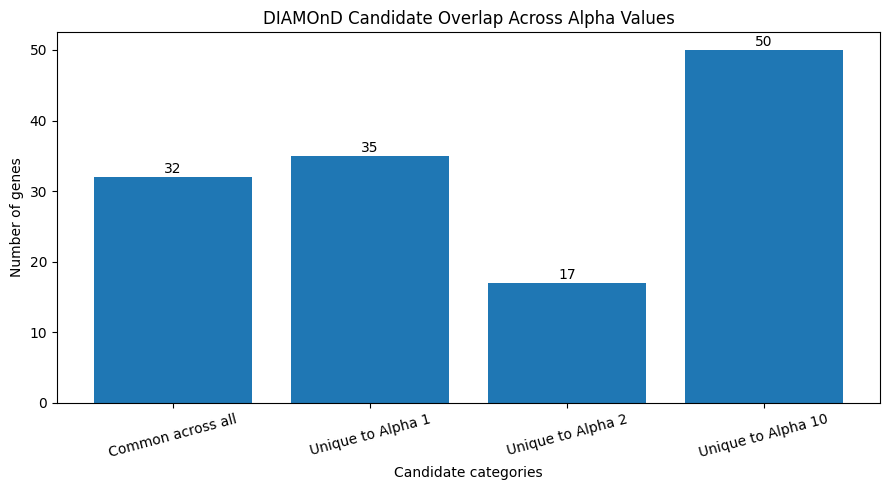

In [63]:
import matplotlib.pyplot as plt

categories = [
    "Common across all",
    "Unique to Alpha 1",
    "Unique to Alpha 2",
    "Unique to Alpha 10"
]

counts = [
    len(common_all),
    len(unique1),
    len(unique2),
    len(unique10)
]

plt.figure(figsize=(9, 5))

bars = plt.bar(categories, counts)

plt.title("DIAMOnD Candidate Overlap Across Alpha Values")
plt.xlabel("Candidate categories")
plt.ylabel("Number of genes")
plt.xticks(rotation=15)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.5,
        str(int(height)),
        ha="center"
    )

plt.tight_layout()
plt.show()

In [64]:
!pip install matplotlib-venn

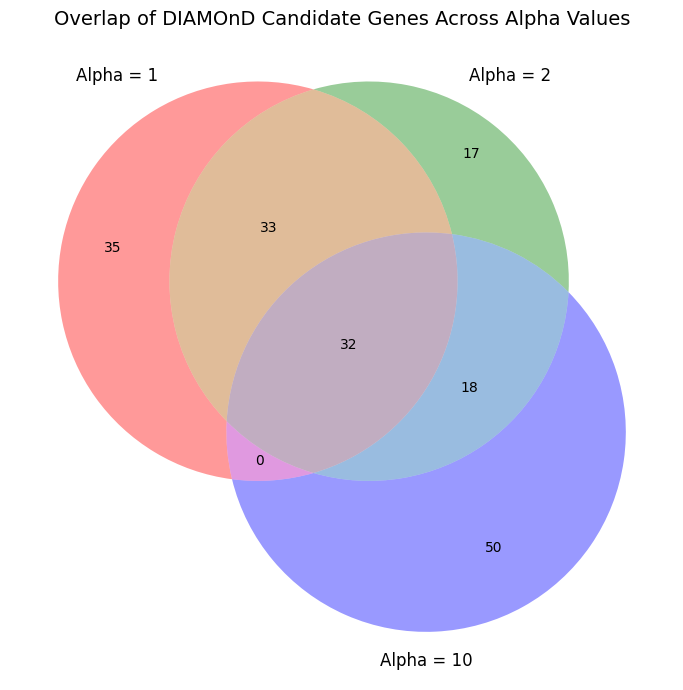

In [65]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn3

plt.figure(figsize=(9, 7))

venn3(
    [genes1, genes2, genes10],
    set_labels=("Alpha = 1", "Alpha = 2", "Alpha = 10")
)

plt.title("Overlap of DIAMOnD Candidate Genes Across Alpha Values",
          fontsize=14)

plt.tight_layout()
plt.savefig("DIAMOnD_Alpha_Venn_Diagram.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [66]:

# Check whether our previous results are still available

print("Alpha 1:", "results_alpha1" in globals())
print("Alpha 2:", "results_alpha2" in globals())
print("Alpha 10:", "results_alpha10" in globals())
print("Gene mapping:", "gene_map" in globals())


Alpha 1: True
Alpha 2: True
Alpha 10: True
Gene mapping: True


In [69]:

# Inspect the predicted genes and gene mapping

print("ALPHA 1 RESULTS:")
display(results_alpha1.head(10))

print("\nGENE MAPPING:")
display(gene_map.head(10))

print("\nCOLUMN NAMES:")
print("Results:", results_alpha1.columns.tolist())
print("Gene map:", gene_map.columns.tolist())


ALPHA 1 RESULTS:


,#rank,DIAMOnD_node,Gene_ID,Gene_Symbol
0,1,51295,51295,ECSIT
1,2,140545,140545,RNF32
2,3,2639,2639,GCDH
3,4,54536,54536,EXOC6
4,5,22983,22983,MAST1
5,6,84171,84171,LOXL4
6,7,11140,11140,CDC37
7,8,84106,84106,PRAM1
8,9,9361,9361,LONP1
9,10,2,2,A2M



GENE MAPPING:


AttributeError: 'dict' object has no attribute 'head'

In [70]:

print("Type of gene_map:", type(gene_map))

print("\nFirst 10 entries in gene_map:")
for i, (gene_id, gene_symbol) in enumerate(gene_map.items()):
    print(gene_id, ":", gene_symbol)
    if i == 9:
        break



Type of gene_map: <class 'dict'>

First 10 entries in gene_map:
1 : A1BG
2 : A2M
10 : NAT2
12 : SERPINA3
14 : AAMP
15 : AANAT
16 : AARS
18 : ABAT
19 : ABCA1
20 : ABCA2


In [71]:

# Extract gene symbols from Alpha 1 predictions

alpha1_candidates = results_alpha1["Gene_Symbol"].dropna().astype(str).tolist()

print("Total predicted genes:", len(alpha1_candidates))
print("Unique genes:", len(set(alpha1_candidates)))

print("\nFirst 20 candidate genes:")
print(alpha1_candidates[:20])


Total predicted genes: 100
Unique genes: 100

First 20 candidate genes:
['ECSIT', 'RNF32', 'GCDH', 'EXOC6', 'MAST1', 'LOXL4', 'CDC37', 'PRAM1', 'LONP1', 'A2M', 'IFIT5', 'IFIT3', 'RAD23A', 'PRDX2', 'ELAVL3', 'EXOSC1', 'NOS3', 'FBXW4', 'CYP2C8', 'BLMH']


In [72]:

import requests
import pandas as pd

# Convert gene symbols to Ensembl IDs using MyGene.info
url = "https://mygene.info/v3/query"

response = requests.post(
    url,
    json={
        "q": ",".join(alpha1_candidates),
        "scopes": "symbol",
        "fields": "symbol,ensembl.gene",
        "species": "human",
        "size": 100
    }
)

print("Status code:", response.status_code)

gene_data = response.json()

print("Number of returned records:", len(gene_data))

# Inspect first 5 records
for item in gene_data[:5]:
    print(item)


Status code: 200
Number of returned records: 102
{'query': 'ECSIT', '_id': '51295', '_score': 148.79999, 'ensembl': {'gene': 'ENSG00000130159'}, 'symbol': 'ECSIT'}
{'query': 'RNF32', '_id': '140545', '_score': 148.79999, 'ensembl': {'gene': 'ENSG00000105982'}, 'symbol': 'RNF32'}
{'query': 'GCDH', '_id': '2639', '_score': 148.79999, 'ensembl': {'gene': 'ENSG00000105607'}, 'symbol': 'GCDH'}
{'query': 'EXOC6', '_id': '54536', '_score': 148.79999, 'ensembl': {'gene': 'ENSG00000138190'}, 'symbol': 'EXOC6'}
{'query': 'MAST1', '_id': '22983', '_score': 148.79999, 'ensembl': {'gene': 'ENSG00000105613'}, 'symbol': 'MAST1'}


In [73]:
# Organise the returned records into a clean table
gene_rows = []

for item in gene_data:
    ensembl = item.get("ensembl")

    if isinstance(ensembl, dict):
        ensembl_ids = [ensembl.get("gene")]
    elif isinstance(ensembl, list):
        ensembl_ids = [x.get("gene") for x in ensembl if x.get("gene")]
    else:
        ensembl_ids = []

    gene_rows.append({
        "Gene_Symbol": item.get("symbol"),
        "Ensembl_IDs": ensembl_ids
    })

gene_mapping_df = pd.DataFrame(gene_rows)

# Identify symbols that appear more than once
duplicate_symbols = (
    gene_mapping_df["Gene_Symbol"]
    .value_counts()
    .loc[lambda x: x > 1]
)

# Identify candidate genes with no Ensembl ID
missing_genes = [
    gene for gene in alpha1_candidates
    if gene not in gene_mapping_df["Gene_Symbol"].values
]

print("Total returned records:", len(gene_mapping_df))
print("Duplicate symbols:")
print(duplicate_symbols)

print("\nGenes without a returned record:")
print(missing_genes)

print("\nFirst 10 mapping records:")
display(gene_mapping_df.head(10))

Total returned records: 102
Duplicate symbols:
Series([], Name: count, dtype: int64)

Genes without a returned record:
['MGEA5']

First 10 mapping records:


,Gene_Symbol,Ensembl_IDs
0,ECSIT,[ENSG00000130159]
1,RNF32,[ENSG00000105982]
2,GCDH,[ENSG00000105607]
3,EXOC6,[ENSG00000138190]
4,MAST1,[ENSG00000105613]
5,LOXL4,[ENSG00000138131]
6,CDC37,[ENSG00000105401]
7,PRAM1,[ENSG00000133246]
8,LONP1,[ENSG00000196365]
9,A2M,[ENSG00000175899]


In [74]:
# Check MGEA5 separately
mgea5_response = requests.get(
    "https://mygene.info/v3/query",
    params={
        "q": "MGEA5",
        "scopes": "symbol",
        "fields": "symbol,name,ensembl.gene,entrezgene",
        "species": "human",
        "size": 10
    }
)

print("Status:", mgea5_response.status_code)

mgea5_data = mgea5_response.json()

for item in mgea5_data.get("hits", []):
    print(item)

Status: 200
{'_id': '10724', '_score': 101.184, 'ensembl': {'gene': 'ENSG00000198408'}, 'entrezgene': '10724', 'name': 'O-GlcNAcase', 'symbol': 'OGA'}


In [75]:
# Create a clean mapping using the original query symbols
mapping_dict = {}

for item in gene_data:
    original_symbol = item.get("query")
    ensembl = item.get("ensembl")

    if isinstance(ensembl, dict):
        ensembl_id = ensembl.get("gene")
    else:
        ensembl_id = None

    if original_symbol and ensembl_id:
        mapping_dict[original_symbol] = ensembl_id

# Add the MGEA5 mapping found separately
mapping_dict["MGEA5"] = "ENSG00000198408"

# Create final mapping table in original candidate order
final_mapping = pd.DataFrame([
    {
        "Gene_Symbol": gene,
        "Ensembl_ID": mapping_dict.get(gene)
    }
    for gene in alpha1_candidates
])

print("Total candidates:", len(final_mapping))
print("Successfully mapped:", final_mapping["Ensembl_ID"].notna().sum())
print("Unmapped:", final_mapping["Ensembl_ID"].isna().sum())

display(final_mapping.head(15))

Total candidates: 100
Successfully mapped: 98
Unmapped: 2


,Gene_Symbol,Ensembl_ID
0,ECSIT,ENSG00000130159
1,RNF32,ENSG00000105982
2,GCDH,ENSG00000105607
3,EXOC6,ENSG00000138190
4,MAST1,ENSG00000105613
5,LOXL4,ENSG00000138131
6,CDC37,ENSG00000105401
7,PRAM1,ENSG00000133246
8,LONP1,ENSG00000196365
9,A2M,ENSG00000175899


In [76]:
# Display the two genes without Ensembl IDs
unmapped_genes = final_mapping[
    final_mapping["Ensembl_ID"].isna()
]["Gene_Symbol"].tolist()

print("Unmapped genes:", unmapped_genes)

Unmapped genes: ['MAPT', 'AKT3']


In [77]:
missing_symbols = ["MAPT", "AKT3"]

for gene in missing_symbols:
    response = requests.get(
        "https://mygene.info/v3/query",
        params={
            "q": f"symbol:{gene}",
            "scopes": "symbol",
            "fields": "symbol,name,ensembl.gene,entrezgene",
            "species": "human",
            "ensemblonly": "true",
            "size": 5
        }
    )

    print(f"\nResults for {gene}:")
    print(response.json())


Results for MAPT:
{'took': 2, 'total': 1, 'max_score': 18.378096, 'hits': [{'_id': '4137', '_score': 18.378096, 'ensembl': [{'gene': 'ENSG00000186868'}, {'gene': 'ENSG00000276155'}, {'gene': 'ENSG00000277956'}], 'entrezgene': '4137', 'name': 'microtubule associated protein tau', 'symbol': 'MAPT'}]}

Results for AKT3:
{'took': 1, 'total': 1, 'max_score': 18.332546, 'hits': [{'_id': '10000', '_score': 18.332546, 'ensembl': [{'gene': 'ENSG00000275199'}, {'gene': 'ENSG00000117020'}], 'entrezgene': '10000', 'name': 'AKT serine/threonine kinase 3', 'symbol': 'AKT3'}]}


In [78]:
# Add the verified Ensembl IDs
mapping_dict["MAPT"] = "ENSG00000186868"
mapping_dict["AKT3"] = "ENSG00000117020"

# Rebuild the final mapping
final_mapping = pd.DataFrame([
    {
        "Gene_Symbol": gene,
        "Ensembl_ID": mapping_dict.get(gene)
    }
    for gene in alpha1_candidates
])

print("Total candidates:", len(final_mapping))
print("Mapped:", final_mapping["Ensembl_ID"].notna().sum())
print("Unmapped:", final_mapping["Ensembl_ID"].isna().sum())

display(final_mapping.tail(10))

Total candidates: 100
Mapped: 100
Unmapped: 0


,Gene_Symbol,Ensembl_ID
90,TRADD,ENSG00000102871
91,BIRC2,ENSG00000110330
92,BCL10,ENSG00000142867
93,TNFRSF10A,ENSG00000104689
94,HTRA2,ENSG00000115317
95,RAF1,ENSG00000132155
96,BIRC7,ENSG00000101197
97,TNFSF10,ENSG00000121858
98,TRAF2,ENSG00000136560
99,ERN1,ENSG00000178607


In [79]:
import requests

ot_url = "https://api.platform.opentargets.org/api/v4/graphql"

query = """
query {
  search(
    queryString: "Alzheimer disease",
    entityNames: ["disease"],
    page: {index: 0, size: 10}
  ) {
    hits {
      id
      name
      entity
    }
  }
}
"""

response = requests.post(
    ot_url,
    json={"query": query}
)

print("Status code:", response.status_code)

ot_data = response.json()

print(ot_data)

Status code: 200
{'data': {'search': {'hits': [{'id': 'MONDO_0004975', 'name': 'Alzheimer disease', 'entity': 'disease'}, {'id': 'MONDO_0100087', 'name': 'familial Alzheimer disease', 'entity': 'disease'}, {'id': 'MONDO_0015140', 'name': 'early-onset autosomal dominant Alzheimer disease', 'entity': 'disease'}, {'id': 'EFO_1001870', 'name': 'late-onset Alzheimers disease', 'entity': 'disease'}, {'id': 'MONDO_0011913', 'name': 'Alzheimer disease 3', 'entity': 'disease'}, {'id': 'EFO_0009268', 'name': 'family history of Alzheimer’s disease', 'entity': 'disease'}, {'id': 'EFO_0006514', 'name': "Alzheimer's disease biomarker measurement", 'entity': 'disease'}, {'id': 'EFO_0022957', 'name': 'early-onset Alzheimers disease', 'entity': 'disease'}, {'id': 'MONDO_0007088', 'name': 'Alzheimer disease type 1', 'entity': 'disease'}, {'id': 'MONDO_0014265', 'name': 'Alzheimer disease 18', 'entity': 'disease'}]}}}


In [80]:
# Retrieve genes directly associated with Alzheimer's disease
disease_id = "MONDO_0004975"

association_query = """
query {
  disease(efoId: "MONDO_0004975") {
    id
    name
    associatedTargets(
      page: {index: 0, size: 500}
      enableIndirect: false
    ) {
      count
      rows {
        score
        target {
          id
          approvedSymbol
        }
      }
    }
  }
}
"""

response = requests.post(
    ot_url,
    json={"query": association_query}
)

print("Status code:", response.status_code)

association_data = response.json()

if "errors" in association_data:
    print("API errors:", association_data["errors"])
else:
    disease_result = association_data["data"]["disease"]
    association_result = disease_result["associatedTargets"]

    print("Disease:", disease_result["name"])
    print("Total direct associations:", association_result["count"])
    print("Records retrieved:", len(association_result["rows"]))

    # Convert results into a DataFrame
    alzheimer_associations = pd.DataFrame([
        {
            "Ensembl_ID": row["target"]["id"],
            "Gene_Symbol": row["target"]["approvedSymbol"],
            "OT_Score": row["score"]
        }
        for row in association_result["rows"]
    ])

    display(alzheimer_associations.head(10))

Status code: 200
Disease: Alzheimer disease
Total direct associations: 12918
Records retrieved: 500


,Ensembl_ID,Gene_Symbol,OT_Score
0,ENSG00000142192,APP,0.814706
1,ENSG00000064687,ABCA7,0.740492
2,ENSG00000176884,GRIN1,0.700810
3,ENSG00000130203,APOE,0.695513
4,ENSG00000164885,CDK5,0.680226
5,ENSG00000137642,SORL1,0.676620
6,ENSG00000116032,GRIN3B,0.674794
7,ENSG00000138613,APH1B,0.642424
8,ENSG00000087085,ACHE,0.634423
9,ENSG00000030582,GRN,0.629282


In [81]:
# Retrieve all direct Alzheimer's disease associations
all_association_rows = []

page_size = 500
total_records = association_result["count"]
total_pages = (total_records + page_size - 1) // page_size

for page_index in range(total_pages):

    query = f"""
    query {{
      disease(efoId: "MONDO_0004975") {{
        associatedTargets(
          page: {{index: {page_index}, size: {page_size}}}
          enableIndirect: false
        ) {{
          rows {{
            score
            target {{
              id
              approvedSymbol
            }}
          }}
        }}
      }}
    }}
    """

    response = requests.post(
        ot_url,
        json={"query": query}
    )

    data = response.json()

    if "errors" in data:
        print("Error on page:", page_index)
        print(data["errors"])
        break

    rows = data["data"]["disease"]["associatedTargets"]["rows"]
    all_association_rows.extend(rows)

    print(
        f"Page {page_index + 1}/{total_pages}: "
        f"{len(all_association_rows)} records collected"
    )

# Create complete association table
alzheimer_associations = pd.DataFrame([
    {
        "Ensembl_ID": row["target"]["id"],
        "Gene_Symbol": row["target"]["approvedSymbol"],
        "OT_Score": row["score"]
    }
    for row in all_association_rows
])

print("\nTotal records collected:", len(alzheimer_associations))

display(alzheimer_associations.head(10))

Page 1/26: 500 records collected
Page 2/26: 1000 records collected
Page 3/26: 1500 records collected
Page 4/26: 2000 records collected
Page 5/26: 2500 records collected
Page 6/26: 3000 records collected
Page 7/26: 3500 records collected
Page 8/26: 4000 records collected
Page 9/26: 4500 records collected
Page 10/26: 5000 records collected
Page 11/26: 5500 records collected
Page 12/26: 6000 records collected
Page 13/26: 6500 records collected
Page 14/26: 7000 records collected
Page 15/26: 7500 records collected
Page 16/26: 8000 records collected
Page 17/26: 8500 records collected
Page 18/26: 9000 records collected
Page 19/26: 9500 records collected
Page 20/26: 10000 records collected
Page 21/26: 10500 records collected
Page 22/26: 11000 records collected
Page 23/26: 11500 records collected
Page 24/26: 12000 records collected
Page 25/26: 12500 records collected
Page 26/26: 12918 records collected

Total records collected: 12918


,Ensembl_ID,Gene_Symbol,OT_Score
0,ENSG00000142192,APP,0.814706
1,ENSG00000064687,ABCA7,0.740492
2,ENSG00000176884,GRIN1,0.700810
3,ENSG00000130203,APOE,0.695513
4,ENSG00000164885,CDK5,0.680226
5,ENSG00000137642,SORL1,0.676620
6,ENSG00000116032,GRIN3B,0.674794
7,ENSG00000138613,APH1B,0.642424
8,ENSG00000087085,ACHE,0.634423
9,ENSG00000030582,GRN,0.629282


In [85]:
# Compare DIAMOnD candidates with Alzheimer's disease associations

comparison_df = final_mapping.merge(
    alzheimer_associations,
    on="Ensembl_ID",
    how="left",
    suffixes=("_DIAMOnD", "_OpenTargets")
)

# Identify genes found in Open Targets
validated_genes = comparison_df[
    comparison_df["OT_Score"].notna()
].copy()

# Sort matched genes by association score
validated_genes = validated_genes.sort_values(
    by="OT_Score",
    ascending=False
)

print("Total DIAMOnD candidates:", len(final_mapping))
print("Genes matched in Open Targets:", len(validated_genes))
print("Genes without a direct association:",
      len(final_mapping) - len(validated_genes))

print("\nTop matched genes:")
display(
    validated_genes[
        ["Gene_Symbol", "Ensembl_ID", "OT_Score"]
    ].head(20)
)

Total DIAMOnD candidates: 100
Genes matched in Open Targets: 94
Genes without a direct association: 6

Top matched genes:


KeyError: "['Gene_Symbol'] not in index"

In [86]:
# Compare DIAMOnD candidates with Alzheimer's disease associations

comparison_df = final_mapping.merge(
    alzheimer_associations,
    on="Ensembl_ID",
    how="left",
    suffixes=("_DIAMOnD", "_OpenTargets")
)

# Identify genes found in Open Targets
validated_genes = comparison_df[
    comparison_df["OT_Score"].notna()
].copy()

# Sort matched genes by association score
validated_genes = validated_genes.sort_values(
    by="OT_Score",
    ascending=False
)

print("Total DIAMOnD candidates:", len(final_mapping))
print("Genes matched in Open Targets:", len(validated_genes))
print("Genes without a direct association:",
      len(final_mapping) - len(validated_genes))

print("\nTop matched genes:")
display(
    validated_genes[
        ["Gene_Symbol", "Ensembl_ID", "OT_Score"]
    ].head(20)
)

Total DIAMOnD candidates: 100
Genes matched in Open Targets: 94
Genes without a direct association: 6

Top matched genes:


KeyError: "['Gene_Symbol'] not in index"

In [87]:
print("Available columns:")
print(validated_genes.columns.tolist())

print("\nTop 20 matched genes:")

display(
    validated_genes[
        ["Gene_Symbol_DIAMOnD", "Ensembl_ID", "OT_Score"]
    ].head(20)
)

Available columns:
['Gene_Symbol_DIAMOnD', 'Ensembl_ID', 'Gene_Symbol_OpenTargets', 'OT_Score']

Top 20 matched genes:


,Gene_Symbol_DIAMOnD,Ensembl_ID,OT_Score
22,CDK5,ENSG00000164885,0.680226
13,PRDX2,ENSG00000167815,0.454832
90,RIPK1,ENSG00000137275,0.442121
74,HTT,ENSG00000108576,0.398745
28,MAPT,ENSG00000186868,0.346893
70,AKT1,ENSG00000142208,0.281377
99,TRAF2,ENSG00000136560,0.273007
26,UMPS,ENSG00000114491,0.196184
21,MGEA5,ENSG00000198408,0.162930
16,NOS3,ENSG00000164867,0.135160


In [88]:
unmatched_genes = comparison_df[
    comparison_df["OT_Score"].isna()
]

print("Genes without direct Open Targets association:")
display(
    unmatched_genes[
        ["Gene_Symbol", "Ensembl_ID"]
    ]
)

Genes without direct Open Targets association:


KeyError: "['Gene_Symbol'] not in index"

In [89]:
unmatched_genes = comparison_df[
    comparison_df["OT_Score"].isna()
]

print("Number of unmatched genes:", len(unmatched_genes))

display(
    unmatched_genes[
        ["Gene_Symbol_DIAMOnD", "Ensembl_ID"]
    ]
)

Number of unmatched genes: 7


,Gene_Symbol_DIAMOnD,Ensembl_ID
1,RNF32,ENSG00000105982
12,RAD23A,ENSG00000179262
17,FBXW4,ENSG00000107829
23,FBXL12,ENSG00000127452
55,BCL2L10,ENSG00000137875
56,AVEN,ENSG00000169857
71,BMF,ENSG00000104081


In [90]:
# Final biological validation statistics

total_candidates = len(final_mapping)
matched_count = len(validated_genes)
unmatched_count = len(unmatched_genes)

match_percentage = (matched_count / total_candidates) * 100

print("DIAMOnD Biological Validation")
print("--------------------------------")
print("Total predicted genes:", total_candidates)
print("Genes with direct OT association:", matched_count)
print("Genes without direct OT association:", unmatched_count)
print("Direct association match rate:", round(match_percentage, 2), "%")

# Save the results
validated_genes.to_csv(
    "DIAMOnD_Alzheimer_Validated_Genes.csv",
    index=False
)

unmatched_genes.to_csv(
    "DIAMOnD_Unmatched_Genes.csv",
    index=False
)

print("\nCSV files saved successfully!")

DIAMOnD Biological Validation
--------------------------------
Total predicted genes: 100
Genes with direct OT association: 94
Genes without direct OT association: 7
Direct association match rate: 94.0 %

CSV files saved successfully!


In [91]:
print("Original DIAMOnD candidates:", len(final_mapping))
print("Unique DIAMOnD Ensembl IDs:", final_mapping["Ensembl_ID"].nunique())

print("\nComparison rows:", len(comparison_df))
print("Matched rows:", len(validated_genes))
print("Unmatched rows:", len(unmatched_genes))

print("\nDuplicate Ensembl IDs in DIAMOnD:")
print(final_mapping[
    final_mapping["Ensembl_ID"].duplicated(keep=False)
])

print("\nDuplicate Ensembl IDs in Open Targets:")
print(alzheimer_associations[
    alzheimer_associations["Ensembl_ID"].duplicated(keep=False)
].head(20))

Original DIAMOnD candidates: 100
Unique DIAMOnD Ensembl IDs: 100

Comparison rows: 101
Matched rows: 94
Unmatched rows: 7

Duplicate Ensembl IDs in DIAMOnD:
Empty DataFrame
Columns: [Gene_Symbol, Ensembl_ID]
Index: []

Duplicate Ensembl IDs in Open Targets:
           Ensembl_ID Gene_Symbol  OT_Score
7495  ENSG00000153006    SREK1IP1  0.009609
7496  ENSG00000175879       HOXD8  0.009609
7497  ENSG00000101844       ATG4A  0.009609
7498  ENSG00000187772      LIN28B  0.009609
7506  ENSG00000187772      LIN28B  0.009609
7507  ENSG00000153006    SREK1IP1  0.009609
7508  ENSG00000175879       HOXD8  0.009609
7509  ENSG00000101844       ATG4A  0.009609
8438  ENSG00000240386       LCE1F  0.007392
8439  ENSG00000113389        NPR3  0.007392
8440  ENSG00000074696       HACD3  0.007392
8441  ENSG00000214313     AZGP1P1  0.007392
8442  ENSG00000075399      VPS9D1  0.007392
8443  ENSG00000166923       GREM1  0.007392
8444  ENSG00000141556        TBCD  0.007392
8445  ENSG00000105856        HBP1  0.0

In [92]:
# Remove duplicate Ensembl IDs from Open Targets
ot_clean = (
    alzheimer_associations
    .sort_values("OT_Score", ascending=False)
    .drop_duplicates(subset="Ensembl_ID", keep="first")
)

print("Original Open Targets records:", len(alzheimer_associations))
print("Unique Open Targets genes:", ot_clean["Ensembl_ID"].nunique())
print("Duplicate records removed:",
      len(alzheimer_associations) - len(ot_clean))

Original Open Targets records: 12918
Unique Open Targets genes: 12397
Duplicate records removed: 521


In [93]:
# Merge using unique Ensembl IDs
comparison_df = final_mapping.merge(
    ot_clean,
    on="Ensembl_ID",
    how="left",
    suffixes=("_DIAMOnD", "_OpenTargets"),
    validate="one_to_one"
)

validated_genes = comparison_df[
    comparison_df["OT_Score"].notna()
].copy()

unmatched_genes = comparison_df[
    comparison_df["OT_Score"].isna()
].copy()

print("Total DIAMOnD candidates:", len(comparison_df))
print("Unique matched genes:", len(validated_genes))
print("Unmatched genes:", len(unmatched_genes))
print("Match percentage:",
      round(len(validated_genes) / len(comparison_df) * 100, 2), "%")

display(
    validated_genes[
        ["Gene_Symbol_DIAMOnD", "Ensembl_ID", "OT_Score"]
    ].sort_values("OT_Score", ascending=False).head(20)
)

Total DIAMOnD candidates: 100
Unique matched genes: 93
Unmatched genes: 7
Match percentage: 93.0 %


,Gene_Symbol_DIAMOnD,Ensembl_ID,OT_Score
22,CDK5,ENSG00000164885,0.680226
13,PRDX2,ENSG00000167815,0.454832
89,RIPK1,ENSG00000137275,0.442121
73,HTT,ENSG00000108576,0.398745
28,MAPT,ENSG00000186868,0.346893
69,AKT1,ENSG00000142208,0.281377
98,TRAF2,ENSG00000136560,0.273007
26,UMPS,ENSG00000114491,0.196184
21,MGEA5,ENSG00000198408,0.162930
16,NOS3,ENSG00000164867,0.135160


In [94]:
# Identify original seed genes
seed_ids = set(
    pd.read_csv("seed_genes.txt", header=None)[0]
    .astype(str)
)

# Map seed IDs to gene symbols
seed_symbols = {
    gene_map[int(gene_id)]
    for gene_id in seed_ids
    if int(gene_id) in gene_map
}

# Compare seed genes with DIAMOnD candidates
candidate_symbols = set(alpha1_candidates)

seed_overlap = candidate_symbols.intersection(seed_symbols)
new_predictions = candidate_symbols - seed_symbols

print("Original seed genes:", len(seed_symbols))
print("Seed genes appearing in top 100:", len(seed_overlap))
print("New predicted genes:", len(new_predictions))

print("\nSeed overlap:")
print(sorted(seed_overlap))

print("\nFirst 20 new predictions:")
print(sorted(new_predictions)[:20])

Original seed genes: 0
Seed genes appearing in top 100: 0
New predicted genes: 100

Seed overlap:
[]

First 20 new predictions:
['A2M', 'AKT1', 'AKT2', 'AKT3', 'APAF1', 'ARHGDIA', 'AVEN', 'BAD', 'BAK1', 'BAX', 'BBC3', 'BCAP31', 'BCL10', 'BCL2', 'BCL2A1', 'BCL2L1', 'BCL2L10', 'BCL2L11', 'BCL2L2', 'BID']


In [95]:
# Inspect the original seed file
with open("seed_genes.txt", "r") as f:
    for i in range(15):
        line = f.readline()
        print(repr(line))

'10452\n'
'10913\n'
'1191\n'
'1378\n'
'2041\n'
'23036\n'
'23607\n'
'25902\n'
'2629\n'
'274\n'
'341\n'
'344558\n'
'348\n'
'351\n'
'4535\n'


In [96]:
print("Number of entries in gene_map:", len(gene_map))

print("\nFirst 10 gene_map entries:")
print(list(gene_map.items())[:10])

print("\nData type of first key:")
print(type(next(iter(gene_map.keys()))))

Number of entries in gene_map: 13459

First 10 gene_map entries:
[('1', 'A1BG'), ('2', 'A2M'), ('10', 'NAT2'), ('12', 'SERPINA3'), ('14', 'AAMP'), ('15', 'AANAT'), ('16', 'AARS'), ('18', 'ABAT'), ('19', 'ABCA1'), ('20', 'ABCA2')]

Data type of first key:
<class 'str'>


In [97]:
# Read seed IDs as strings
seed_ids = set(
    pd.read_csv("seed_genes.txt", header=None)[0]
    .astype(str).str.strip()
)

# Convert seed IDs into gene symbols
seed_symbols = {
    gene_map[gene_id]
    for gene_id in seed_ids
    if gene_id in gene_map
}

# Get the Alpha1 candidate genes
candidate_symbols = set(alpha1_candidates)

# Compare seeds with predictions
seed_overlap = candidate_symbols.intersection(seed_symbols)
new_predictions = candidate_symbols - seed_symbols

print("Original seed genes:", len(seed_symbols))
print("Seed genes appearing in top 100:", len(seed_overlap))
print("New predicted genes:", len(new_predictions))
print("Seed overlap:", sorted(seed_overlap))

Original seed genes: 29
Seed genes appearing in top 100: 0
New predicted genes: 100
Seed overlap: []


In [98]:
import matplotlib.pyplot as plt
import pandas as pd

# Select the 20 genes with the highest Open Targets scores
top20_genes = (
    validated_genes
    .sort_values(by="OT_Score", ascending=False)
    .head(20)
    .copy()
)

# Display the selected genes
display(
    top20_genes[["Gene_Symbol_DIAMOnD", "OT_Score"]]
)

,Gene_Symbol_DIAMOnD,OT_Score
22,CDK5,0.680226
13,PRDX2,0.454832
89,RIPK1,0.442121
73,HTT,0.398745
28,MAPT,0.346893
69,AKT1,0.281377
98,TRAF2,0.273007
26,UMPS,0.196184
21,MGEA5,0.162930
16,NOS3,0.135160


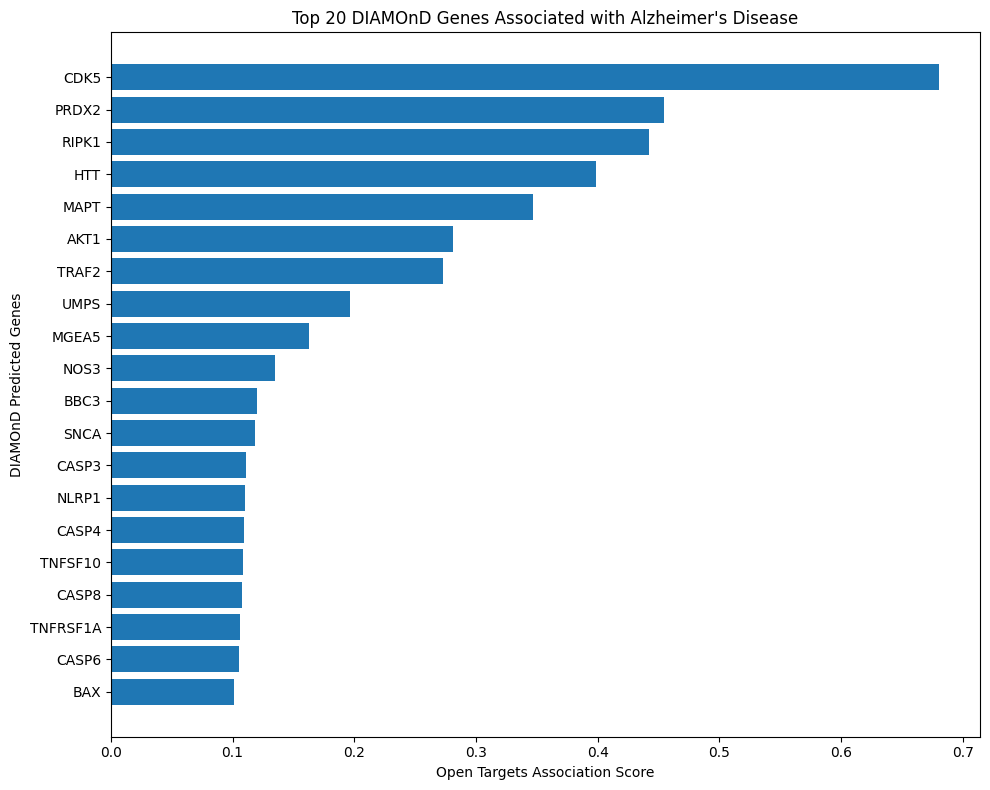

In [99]:
# Sort scores in ascending order for a clean horizontal chart
plot_data = top20_genes.sort_values(
    by="OT_Score",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    plot_data["Gene_Symbol_DIAMOnD"],
    plot_data["OT_Score"]
)

plt.xlabel("Open Targets Association Score")
plt.ylabel("DIAMOnD Predicted Genes")
plt.title("Top 20 DIAMOnD Genes Associated with Alzheimer's Disease")

plt.tight_layout()
plt.show()

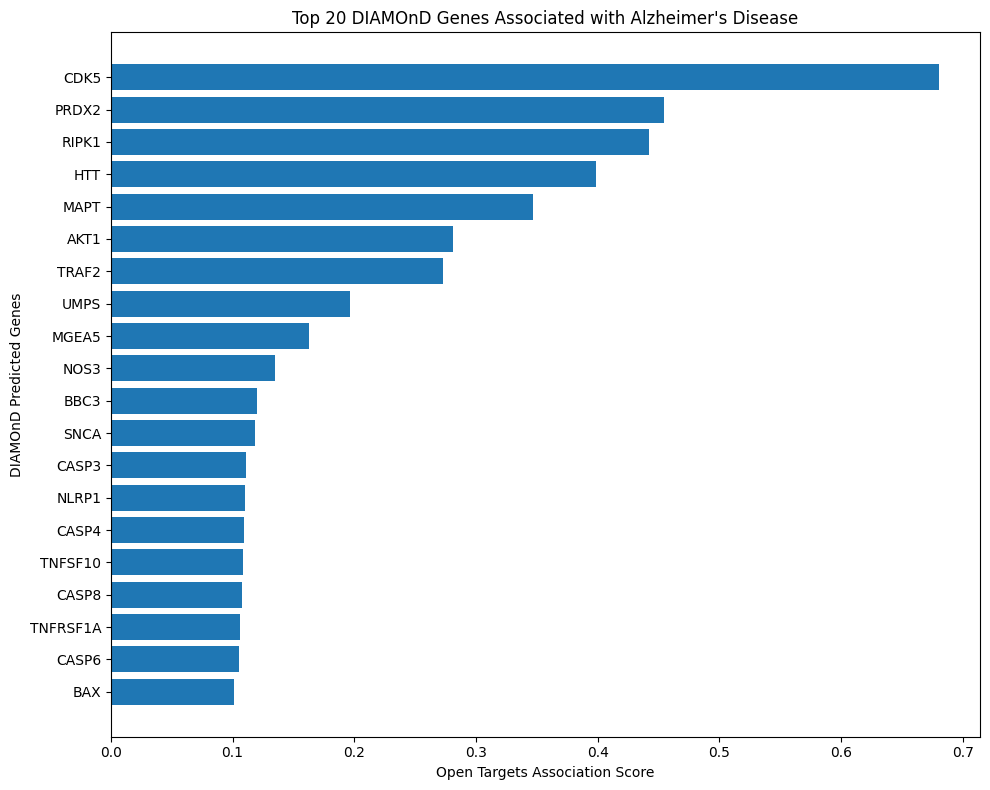

In [100]:
plt.figure(figsize=(10, 8))

plt.barh(
    plot_data["Gene_Symbol_DIAMOnD"],
    plot_data["OT_Score"]
)

plt.xlabel("Open Targets Association Score")
plt.ylabel("DIAMOnD Predicted Genes")
plt.title("Top 20 DIAMOnD Genes Associated with Alzheimer's Disease")

plt.tight_layout()

plt.savefig(
    "Alzheimer_DIAMOnD_OpenTargets_Top20.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [101]:
# Collect predictions for each alpha value
alpha_results = {
    "Alpha 1": results_alpha1,
    "Alpha 2": results_alpha2,
    "Alpha 10": results_alpha10
}

validation_summary = []

for alpha_name, result_df in alpha_results.items():

    # Extract predicted gene symbols
    genes = set(result_df["Gene_Symbol"].dropna().astype(str))

    # Find corresponding Open Targets records
    matched = ot_clean[ot_clean["Gene_Symbol"].isin(genes)]

    validation_summary.append({
        "Alpha": alpha_name,
        "Total_Predicted": len(genes),
        "Matched_Genes": matched["Gene_Symbol"].nunique(),
        "Unmatched_Genes": len(genes) - matched["Gene_Symbol"].nunique(),
        "Match_Percentage": (
            matched["Gene_Symbol"].nunique() / len(genes)
        ) * 100,
        "Average_OT_Score": matched["OT_Score"].mean()
    })

validation_summary_df = pd.DataFrame(validation_summary)

display(validation_summary_df.round(4))

,Alpha,Total_Predicted,Matched_Genes,Unmatched_Genes,Match_Percentage,Average_OT_Score
0,Alpha 1,100,92,8,92.0,0.0726
1,Alpha 2,100,94,6,94.0,0.1272
2,Alpha 10,100,98,2,98.0,0.1498


In [102]:
# Correct the known gene-symbol difference
symbol_aliases = {
    "MGEA5": "OGA"
}

def standardize_symbol(gene):
    return symbol_aliases.get(gene, gene)

validation_summary = []

for alpha_name, result_df in alpha_results.items():

    genes = set(
        result_df["Gene_Symbol"]
        .dropna()
        .astype(str)
        .apply(standardize_symbol)
    )

    matched = ot_clean[
        ot_clean["Gene_Symbol"].isin(genes)
    ]

    matched_count = matched["Gene_Symbol"].nunique()

    validation_summary.append({
        "Alpha": alpha_name,
        "Total_Predicted": len(genes),
        "Matched_Genes": matched_count,
        "Unmatched_Genes": len(genes) - matched_count,
        "Match_Percentage": matched_count / len(genes) * 100,
        "Average_OT_Score": matched["OT_Score"].mean()
    })

validation_summary_df = pd.DataFrame(validation_summary)

display(validation_summary_df.round(4))

,Alpha,Total_Predicted,Matched_Genes,Unmatched_Genes,Match_Percentage,Average_OT_Score
0,Alpha 1,100,93,7,93.0,0.0735
1,Alpha 2,100,95,5,95.0,0.1276
2,Alpha 10,100,98,2,98.0,0.1498


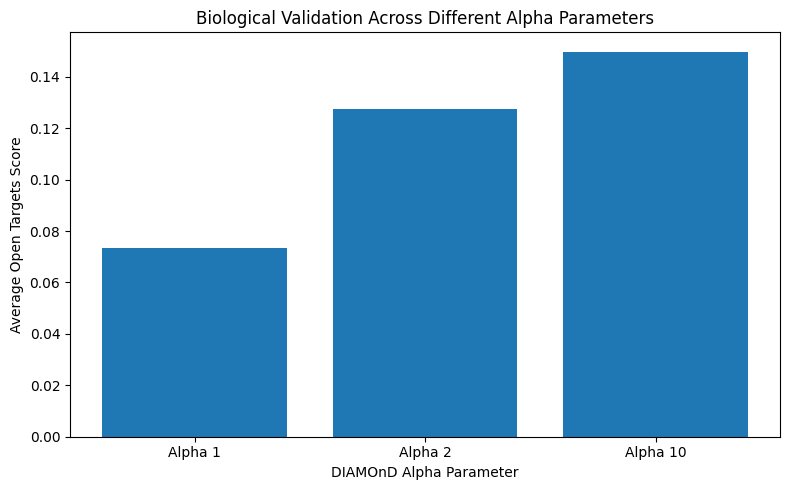

In [103]:
plt.figure(figsize=(8, 5))

plt.bar(
    validation_summary_df["Alpha"],
    validation_summary_df["Average_OT_Score"]
)

plt.xlabel("DIAMOnD Alpha Parameter")
plt.ylabel("Average Open Targets Score")
plt.title("Biological Validation Across Different Alpha Parameters")

plt.tight_layout()

plt.savefig(
    "Alzheimer_Alpha_Validation_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [104]:
alpha10_genes = (
    results_alpha10["Gene_Symbol"]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)

print("Total Alpha10 genes:", len(alpha10_genes))
print("Unique genes:", len(set(alpha10_genes)))
print("\nFirst 10 genes:", alpha10_genes[:10])

Total Alpha10 genes: 100
Unique genes: 100

First 10 genes: ['ECSIT', 'RNF32', 'GCDH', 'EXOC6', 'MAPT', 'CASP6', 'CASP1', 'CASP4', 'SNCA', 'BCL2L1']


In [105]:
import requests
import pandas as pd

# Submit Alpha10 genes to Enrichr
url = "https://maayanlab.cloud/Enrichr/addList"

gene_list = "\n".join(alpha10_genes)

response = requests.post(
    url,
    files={
        "list": (None, gene_list),
        "description": (None, "DIAMOnD Alpha10 Alzheimer candidates")
    },
    timeout=60
)

response.raise_for_status()
enrichr_result = response.json()

user_list_id = enrichr_result["userListId"]

print("Genes submitted:", len(alpha10_genes))
print("Enrichr submission successful:", user_list_id)

Genes submitted: 100
Enrichr submission successful: 141801993


In [106]:
# Retrieve enrichment results
libraries = ["KEGG_2021_Human", "Reactome_2022"]

all_pathway_results = []

for library in libraries:

    response = requests.get(
        "https://maayanlab.cloud/Enrichr/enrich",
        params={
            "userListId": user_list_id,
            "backgroundType": library
        },
        timeout=60
    )

    response.raise_for_status()
    data = response.json()

    if library not in data:
        print("No results returned for:", library)
        continue

    for item in data[library]:
        all_pathway_results.append({
            "Database": library,
            "Pathway": item[1],
            "P_Value": item[2],
            "Combined_Score": item[4],
            "Genes": ", ".join(item[5]),
            "Adjusted_P_Value": item[6]
        })

pathway_df = pd.DataFrame(all_pathway_results)

if pathway_df.empty:
    print("No pathway results returned. We need to check the API response.")
else:
    pathway_df = pathway_df.sort_values(
        "Adjusted_P_Value",
        ascending=True
    )

    significant_pathways = pathway_df[
        pathway_df["Adjusted_P_Value"] < 0.05
    ]

    print("Total pathways retrieved:", len(pathway_df))
    print("Significant pathways (adjusted p-value < 0.05):",
          len(significant_pathways))

    display(significant_pathways.head(15))

Total pathways retrieved: 1089
Significant pathways (adjusted p-value < 0.05): 616


,Database,Pathway,P_Value,Combined_Score,Genes,Adjusted_P_Value
200,Reactome_2022,Signaling By Receptor Tyrosine Kinases R-HSA-9...,3.278252e-35,2065.880504,"IRS1, YWHAB, SRC, PIK3R1, CBL, PRKCZ, IGF1R, U...",2.914366e-32
0,KEGG_2021_Human,Pathways in cancer,2.087227e-27,1178.867004,"RB1, CDKN1A, CDKN1B, PIK3R1, CBL, IGF1R, MAPK9...",4.174455e-25
1,KEGG_2021_Human,ErbB signaling pathway,1.019269e-26,4218.766792,"STAT5A, CDKN1A, MAP2K1, CDKN1B, PRKCB, SRC, BA...",1.019269e-24
201,Reactome_2022,Cytokine Signaling In Immune System R-HSA-1280215,4.223834e-27,986.539384,"CDKN1A, CDKN1B, IRS1, IFIT5, PIK3R1, CBL, IFIT...",1.877494e-24
2,KEGG_2021_Human,PI3K-Akt signaling pathway,4.744020e-26,1361.548135,"YWHAE, ATF2, CDKN1A, CDKN1B, IRS1, YWHAB, PIK3...",3.162680e-24
3,KEGG_2021_Human,Chronic myeloid leukemia,7.529344e-26,4344.176782,"RB1, STAT5A, CDKN1A, MAP2K1, CDKN1B, BAD, PTPN...",3.764672e-24
202,Reactome_2022,Signal Transduction R-HSA-162582,1.403883e-26,573.205648,"YWHAE, CDKN1A, CDKN1B, IRS1, YWHAB, IGF1R, LMN...",4.160174e-24
203,Reactome_2022,Programmed Cell Death R-HSA-5357801,2.649243e-26,1992.791492,"YWHAE, HSP90AA1, BAD, YWHAB, PRKCD, STAT3, LMN...",5.887942e-24
4,KEGG_2021_Human,Non-small cell lung cancer,1.981515e-24,4033.465020,"RB1, STAT5A, CDKN1A, MAP2K1, PDPK1, PRKCB, BAD...",7.926061e-23
5,KEGG_2021_Human,Hepatitis B,3.729070e-24,2009.538636,"RB1, STAT5A, ATF2, MAP2K1, CDKN1A, BAD, PRKCB,...",1.243023e-22


In [107]:
# Save all pathway results
pathway_df.to_csv(
    "DIAMOnD_Alpha10_All_Pathways.csv",
    index=False
)

# Save statistically significant pathways
significant_pathways.to_csv(
    "DIAMOnD_Alpha10_Significant_Pathways.csv",
    index=False
)

print("All pathways:", len(pathway_df))
print("Significant pathways:", len(significant_pathways))
print("Files saved successfully!")

All pathways: 1089
Significant pathways: 616
Files saved successfully!


In [108]:
from google.colab import files

files.download("DIAMOnD_Alpha10_All_Pathways.csv")
files.download("DIAMOnD_Alpha10_Significant_Pathways.csv")
files.download("DIAMOnD_Alzheimer_Validated_Genes.csv")
files.download("Alzheimer_DIAMOnD_OpenTargets_Top20.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [109]:
from google.colab import files

files.download("DIAMOnD_Alpha10_Significant_Pathways.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [110]:
files.download("DIAMOnD_Alpha10_All_Pathways.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [111]:
from google.colab import files

files.download("DIAMOnD_Alpha10_Significant_Pathways.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [112]:
files.download("DIAMOnD_Alpha10_All_Pathways.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [113]:
files.download("DIAMOnD_Alpha10_All_Pathways.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>